In [10]:

# STEP 1: Download and inspect Online Retail II

import os
import zipfile
import requests
import pandas as pd

# Official UCI dataset archive
url = (
    "https://archive.ics.uci.edu/static/public/502/"
    "online+retail+ii.zip"
)

os.makedirs("/content/retail_project", exist_ok=True)

zip_path = "/content/retail_project/retail_data.zip"

# Download the dataset
response = requests.get(url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

# Extract the archive
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/retail_project")

# Locate the Excel workbook
excel_files = []

for root, dirs, files in os.walk(
    "/content/retail_project"
):
    for filename in files:
        if filename.lower().endswith(".xlsx"):
            excel_files.append(
                os.path.join(root, filename)
            )

print("EXCEL FILES FOUND:")
print(excel_files)

if not excel_files:
    raise FileNotFoundError("No Excel workbook found.")

excel_path = excel_files[0]

# Inspect workbook sheets
workbook = pd.ExcelFile(excel_path)

print("\nAVAILABLE SHEETS:")
print(workbook.sheet_names)

# Load the first year's transactions
retail_df = pd.read_excel(
    excel_path,
    sheet_name=0
)

print("\nFIRST SHEET LOADED!")

print("\nDATASET SHAPE:")
print(retail_df.shape)

print("\nCOLUMN NAMES:")
print(retail_df.columns.tolist())

print("\nFIRST 5 RECORDS:")
display(retail_df.head())

print("\nDATA TYPES:")
display(retail_df.dtypes.to_frame("Data Type"))


EXCEL FILES FOUND:
['/content/retail_project/online_retail_II.xlsx']

AVAILABLE SHEETS:
['Year 2009-2010', 'Year 2010-2011']

FIRST SHEET LOADED!

DATASET SHAPE:
(525461, 8)

COLUMN NAMES:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

FIRST 5 RECORDS:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



DATA TYPES:


,Data Type
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
Price,float64
Customer ID,float64
Country,object


In [11]:

import pandas as pd

print("1. DATASET OVERVIEW")
print("Rows:", retail_df.shape[0])
print("Columns:", retail_df.shape[1])

print("\n2. MISSING VALUES")

missing_summary = pd.DataFrame({
    "Missing Count": retail_df.isnull().sum(),
    "Missing %": (
        retail_df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

print("\n3. DUPLICATE ROWS")
print(
    "Exact duplicate rows:",
    retail_df.duplicated().sum()
)

print("\n4. UNIQUE VALUES")

print(
    "Unique invoices:",
    retail_df["Invoice"].nunique()
)

print(
    "Unique customers:",
    retail_df["Customer ID"].nunique()
)

print(
    "Unique products:",
    retail_df["StockCode"].nunique()
)

print(
    "Countries:",
    retail_df["Country"].nunique()
)

print("\n5. QUANTITY AND PRICE CHECK")

print(
    "Negative quantities:",
    (retail_df["Quantity"] < 0).sum()
)

print(
    "Zero quantities:",
    (retail_df["Quantity"] == 0).sum()
)

print(
    "Negative prices:",
    (retail_df["Price"] < 0).sum()
)

print(
    "Zero prices:",
    (retail_df["Price"] == 0).sum()
)

print("\n6. TRANSACTION DATE RANGE")

print(
    "Earliest date:",
    retail_df["InvoiceDate"].min()
)

print(
    "Latest date:",
    retail_df["InvoiceDate"].max()
)

print("\n7. TOP 10 COUNTRIES")

display(
    retail_df["Country"]
    .value_counts()
    .head(10)
    .to_frame("Transaction Rows")
)


1. DATASET OVERVIEW
Rows: 525461
Columns: 8

2. MISSING VALUES


,Missing Count,Missing %
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00



3. DUPLICATE ROWS
Exact duplicate rows: 6865

4. UNIQUE VALUES
Unique invoices: 28816
Unique customers: 4383
Unique products: 4632
Countries: 40

5. QUANTITY AND PRICE CHECK
Negative quantities: 12326
Zero quantities: 0
Negative prices: 3
Zero prices: 3687

6. TRANSACTION DATE RANGE
Earliest date: 2009-12-01 07:45:00
Latest date: 2010-12-09 20:01:00

7. TOP 10 COUNTRIES


,Transaction Rows
Country,
United Kingdom,485852
EIRE,9670
Germany,8129
France,5772
Netherlands,2769
Spain,1278
Switzerland,1187
Portugal,1101
Belgium,1054


In [12]:

import pandas as pd

# Preserve the original dataset
eda_df = retail_df.copy()

# Convert invoice identifiers to strings
eda_df["Invoice_Str"] = (
    eda_df["Invoice"].astype(str).str.strip()
)

# Identify canceled invoices
eda_df["Is_Cancellation"] = (
    eda_df["Invoice_Str"]
    .str.upper()
    .str.startswith("C")
)

print("1. CANCELLATION ANALYSIS")

display(pd.DataFrame({
    "Condition": [
        "Invoices starting with C (rows)",
        "Negative quantity rows",
        "Negative quantity in C invoices",
        "Negative quantity in other invoices"
    ],
    "Count": [
        eda_df["Is_Cancellation"].sum(),
        (eda_df["Quantity"] < 0).sum(),
        (
            (eda_df["Quantity"] < 0) &
            eda_df["Is_Cancellation"]
        ).sum(),
        (
            (eda_df["Quantity"] < 0) &
            ~eda_df["Is_Cancellation"]
        ).sum()
    ]
}))

print("\n2. SAMPLE CANCELLATION RECORDS")

display(
    eda_df.loc[
        eda_df["Is_Cancellation"]
    ].head(10)
)

print("\n3. NEGATIVE PRICE RECORDS")

display(
    eda_df.loc[
        eda_df["Price"] < 0
    ]
)

print("\n4. SAMPLE ZERO PRICE RECORDS")

display(
    eda_df.loc[
        eda_df["Price"] == 0
    ].head(15)
)

print("\n5. TOP 10 DESCRIPTIONS WITH NEGATIVE QUANTITY")

display(
    eda_df.loc[
        eda_df["Quantity"] < 0,
        "Description"
    ]
    .value_counts(dropna=False)
    .head(10)
    .to_frame("Occurrences")
)

print("\n6. MISSING CUSTOMER IDs BY TRANSACTION TYPE")

display(
    pd.crosstab(
        eda_df["Is_Cancellation"],
        eda_df["Customer ID"].isna(),
        rownames=["Is Cancellation"],
        colnames=["Customer ID Missing"]
    )
)


1. CANCELLATION ANALYSIS


,Condition,Count
0,Invoices starting with C (rows),10206
1,Negative quantity rows,12326
2,Negative quantity in C invoices,10205
3,Negative quantity in other invoices,2121



2. SAMPLE CANCELLATION RECORDS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Invoice_Str,Is_Cancellation
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,C489449,True
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,C489449,True
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,C489449,True
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,C489449,True
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,C489449,True
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,C489449,True
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,C489449,True
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia,C489449,True
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,C489449,True
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom,C489459,True



3. NEGATIVE PRICE RECORDS


...

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Invoice_Str,Is_Cancellation
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,489464,False
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,489463,False
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,489467,False
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,489521,False
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,489655,False
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom,489659,False
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom,489660,False
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom,489663,False
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom,489781,False
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,489806,False



5. TOP 10 DESCRIPTIONS WITH NEGATIVE QUANTITY


,Occurrences
Description,
NaN,1827
Manual,293
BAKING SET 9 PIECE RETROSPOT,184
REGENCY CAKESTAND 3 TIER,166
STRAWBERRY CERAMIC TRINKET BOX,129
WHITE CHERRY LIGHTS,120
POSTAGE,103
Discount,95
WHITE HANGING HEART T-LIGHT HOLDER,93



6. MISSING CUSTOMER IDs BY TRANSACTION TYPE


Customer ID Missing,False,True
Is Cancellation,,
False,407695,107560
True,9839,367


In [13]:

import pandas as pd

print("1. NEGATIVE QUANTITIES OUTSIDE CANCELLATION INVOICES")

unusual_negative = eda_df[
    (eda_df["Quantity"] < 0) &
    (~eda_df["Is_Cancellation"])
].copy()

print("Total records:", len(unusual_negative))

print("\nTop 15 descriptions:")
display(
    unusual_negative["Description"]
    .value_counts(dropna=False)
    .head(15)
    .to_frame("Records")
)

print("\nSample records:")
display(
    unusual_negative[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "Customer ID"]
    ].head(15)
)

print("\n2. DUPLICATE RECORDS")

duplicate_mask = eda_df.duplicated(
    subset=retail_df.columns.tolist(),
    keep=False
)

duplicate_records = eda_df[
    duplicate_mask
].copy()

print(
    "Rows belonging to duplicate groups:",
    len(duplicate_records)
)

print(
    "Extra duplicate rows:",
    eda_df.duplicated(
        subset=retail_df.columns.tolist()
    ).sum()
)

print("\nSample duplicate groups:")

display(
    duplicate_records.sort_values(
        ["Invoice", "StockCode"],
        key=lambda s: s.astype(str)
    )[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "Customer ID"]
    ].head(20)
)

print("\n3. DUPLICATE GROUPS BY TRANSACTION TYPE")

display(
    pd.crosstab(
        duplicate_records["Is_Cancellation"],
        duplicate_records["Quantity"] > 0,
        rownames=["Cancellation Invoice"],
        colnames=["Positive Quantity"]
    )
)

print("\n4. INVOICE PREFIXES")

eda_df["Invoice_Prefix"] = (
    eda_df["Invoice_Str"]
    .str.extract(r"^([A-Za-z]+)", expand=False)
    .fillna("Numeric")
)

display(
    eda_df["Invoice_Prefix"]
    .value_counts()
    .to_frame("Rows")
)


1. NEGATIVE QUANTITIES OUTSIDE CANCELLATION INVOICES
Total records: 2121

Top 15 descriptions:


,Records
Description,
NaN,1827
?,42
damages,39
damaged,36
missing,24
dotcom,6
given away,6
checked,5
smashed,5



Sample records:


,Invoice,StockCode,Description,Quantity,Price,Customer ID
263,489464,21733,85123a mixed,-96,0.0,NaN
283,489463,71477,short,-240,0.0,NaN
284,489467,85123A,21733 mixed,-192,0.0,NaN
470,489521,21646,NaN,-50,0.0,NaN
3114,489655,20683,NaN,-44,0.0,NaN
3162,489660,35956,lost,-1043,0.0,NaN
3168,489663,35605A,damages,-117,0.0,NaN
4296,489806,18010,NaN,-770,0.0,NaN
4538,489820,21133,invcd as 84879?,-720,0.0,NaN
4566,489821,85049G,NaN,-240,0.0,NaN



2. DUPLICATE RECORDS
Rows belonging to duplicate groups: 13283
Extra duplicate rows: 6865

Sample duplicate groups:


,Invoice,StockCode,Description,Quantity,Price,Customer ID
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,1.95,16329.0
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,1.95,16329.0
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,3.75,16329.0
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,3.75,16329.0
363,489517,21912,VINTAGE SNAKES & LADDERS,1,3.75,16329.0
371,489517,21912,VINTAGE SNAKES & LADDERS,1,3.75,16329.0
394,489517,21912,VINTAGE SNAKES & LADDERS,1,3.75,16329.0
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,3.75,16329.0
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,3.75,16329.0
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,0.85,16329.0



3. DUPLICATE GROUPS BY TRANSACTION TYPE


Positive Quantity,False,True
Cancellation Invoice,,
False,0,13236
True,47,0



4. INVOICE PREFIXES


,Rows
Invoice_Prefix,
Numeric,515252
C,10206
A,3


1. NUMERICAL FEATURE STATISTICS


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,525461.0,10.337667,107.424110,-9600.00,-3.00,1.00,1.00,3.0,10.00,30.00,120.00,19152.00
Price,525461.0,4.688834,146.126914,-53594.36,0.21,0.42,1.25,2.1,4.21,10.17,19.95,25111.09



2. QUANTITY DISTRIBUTION


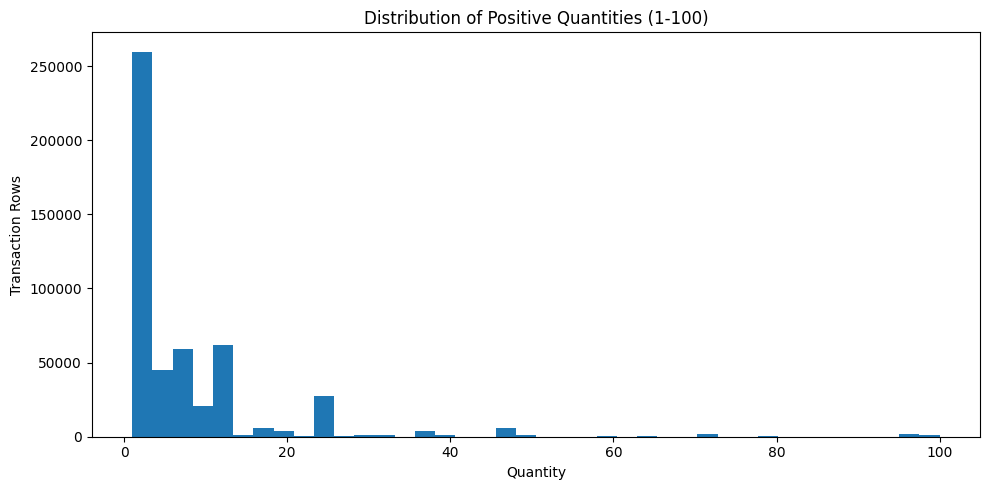


3. PRICE DISTRIBUTION


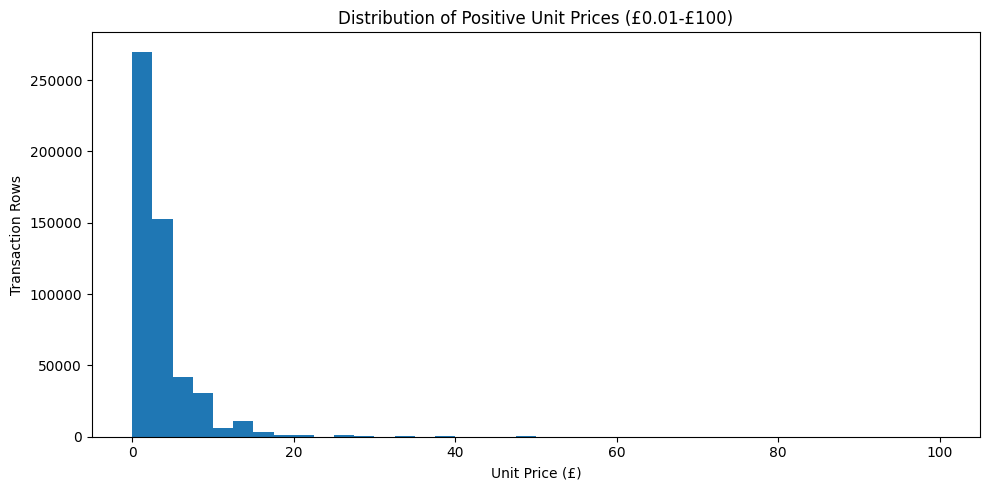


4. POTENTIAL EXTREME VALUES
Quantity above 100: 5611
Quantity below -100: 689
Price above £100: 910

5. LARGEST POSITIVE QUANTITIES


,Invoice,Description,Quantity,Price,Customer ID
90857,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902.0
127166,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902.0
127168,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902.0
127169,501534,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902.0
127167,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902.0
192197,507637,FLAG OF ST GEORGE CAR FLAG,10200,0.00,NaN
135027,502269,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940.0
135028,502269,PACK OF 12 SUKI TISSUES,10000,0.25,17940.0
135029,502269,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940.0
135030,502269,PACK OF 12 WOODLAND TISSUES,10000,0.25,17940.0



6. HIGHEST UNIT PRICES


,Invoice,Description,Quantity,Price,Customer ID
241824,C512770,Manual,-1,25111.09,17399.0
241827,512771,Manual,1,25111.09,NaN
320581,C520667,Bank Charges,-1,18910.69,NaN
517953,C537630,AMAZON FEE,-1,13541.33,NaN
517955,537632,AMAZON FEE,1,13541.33,NaN
519294,C537651,AMAZON FEE,-1,13541.33,NaN
519170,C537644,AMAZON FEE,-1,13474.79,NaN
135012,C502262,Manual,-1,10953.50,12918.0
135013,502263,Manual,1,10953.50,12918.0
135014,C502264,Manual,-1,10953.50,12918.0


In [14]:

import pandas as pd
import matplotlib.pyplot as plt

# Always use the original raw data for EDA
eda_df = retail_df.copy()

print("1. NUMERICAL FEATURE STATISTICS")

display(
    eda_df[["Quantity", "Price"]]
    .describe(percentiles=[
        0.01, 0.05, 0.25,
        0.50, 0.75, 0.95, 0.99
    ]).T
)

print("\n2. QUANTITY DISTRIBUTION")

# Temporary view for visualization only
quantity_view = eda_df.loc[
    eda_df["Quantity"].between(1, 100)
]

plt.figure(figsize=(10, 5))
plt.hist(
    quantity_view["Quantity"],
    bins=40
)
plt.title("Distribution of Positive Quantities (1-100)")
plt.xlabel("Quantity")
plt.ylabel("Transaction Rows")
plt.tight_layout()
plt.show()

print("\n3. PRICE DISTRIBUTION")

# Temporary view for visualization only
price_view = eda_df.loc[
    eda_df["Price"].between(0.01, 100)
]

plt.figure(figsize=(10, 5))
plt.hist(
    price_view["Price"],
    bins=40
)
plt.title("Distribution of Positive Unit Prices (£0.01-£100)")
plt.xlabel("Unit Price (£)")
plt.ylabel("Transaction Rows")
plt.tight_layout()
plt.show()

print("\n4. POTENTIAL EXTREME VALUES")

print(
    "Quantity above 100:",
    (eda_df["Quantity"] > 100).sum()
)

print(
    "Quantity below -100:",
    (eda_df["Quantity"] < -100).sum()
)

print(
    "Price above £100:",
    (eda_df["Price"] > 100).sum()
)

print("\n5. LARGEST POSITIVE QUANTITIES")

display(
    eda_df.nlargest(
        10, "Quantity"
    )[
        [
            "Invoice", "Description",
            "Quantity", "Price",
            "Customer ID"
        ]
    ]
)

print("\n6. HIGHEST UNIT PRICES")

display(
    eda_df.nlargest(
        10, "Price"
    )[
        [
            "Invoice", "Description",
            "Quantity", "Price",
            "Customer ID"
        ]
    ]
)


1. MONTHLY SALES SUMMARY


,Month,Transaction_Lines,Unique_Invoices,Gross_Positive_Value,Identified_Customers
0,2009-12,43957,1682,825685.76,955
1,2010-01,30638,1105,652708.50,720
2,2010-02,28281,1201,553339.74,772
3,2010-03,40364,1681,833570.13,1057
4,2010-04,33268,1462,681528.99,942
5,2010-05,33795,1500,659858.86,966
6,2010-06,38900,1645,752270.14,1041
7,2010-07,32503,1529,650712.94,928
8,2010-08,32473,1425,697274.91,911
9,2010-09,41109,1839,924333.01,1145


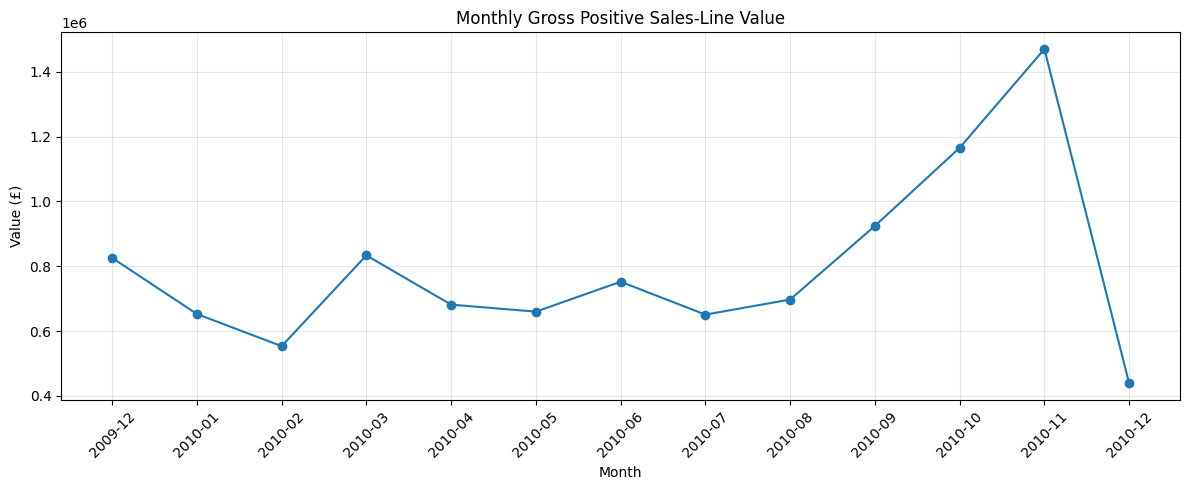

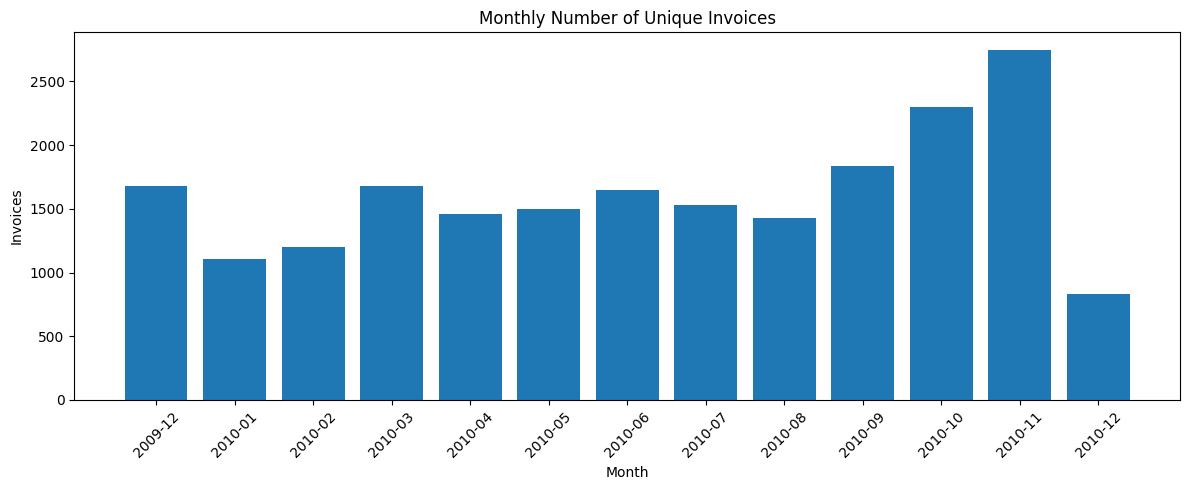


2. HIGHEST SALES MONTH


,Month,Gross_Positive_Value,Unique_Invoices
11,2010-11,1470272.482,2747
10,2010-10,1165483.910,2301
9,2010-09,924333.011,1839



3. LOWEST SALES MONTH


,Month,Gross_Positive_Value,Unique_Invoices
12,2010-12,438852.650,834
2,2010-02,553339.736,1201
7,2010-07,650712.940,1529


In [15]:

import pandas as pd
import matplotlib.pyplot as plt

# Work from the original raw dataset
monthly_eda = retail_df.copy()

# Temporary filter for positive-value transactions
invoice_text = (
    monthly_eda["Invoice"]
    .astype(str)
    .str.strip()
    .str.upper()
)

monthly_eda = monthly_eda.loc[
    (monthly_eda["Quantity"] > 0) &
    (monthly_eda["Price"] > 0) &
    (~invoice_text.str.startswith("C"))
].copy()

# Create temporary analysis features
monthly_eda["Line_Value"] = (
    monthly_eda["Quantity"] *
    monthly_eda["Price"]
)

monthly_eda["Month"] = (
    monthly_eda["InvoiceDate"]
    .dt.to_period("M")
)

# Aggregate monthly statistics
monthly_summary = (
    monthly_eda.groupby("Month")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Gross_Positive_Value=("Line_Value", "sum"),
        Identified_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

monthly_summary["Month"] = (
    monthly_summary["Month"].astype(str)
)

print("1. MONTHLY SALES SUMMARY")
display(monthly_summary.round(2))

# Revenue trend
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_summary["Month"],
    monthly_summary["Gross_Positive_Value"],
    marker="o"
)

plt.title("Monthly Gross Positive Sales-Line Value")
plt.xlabel("Month")
plt.ylabel("Value (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Invoice count trend
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_summary["Month"],
    monthly_summary["Unique_Invoices"]
)

plt.title("Monthly Number of Unique Invoices")
plt.xlabel("Month")
plt.ylabel("Invoices")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\n2. HIGHEST SALES MONTH")

display(
    monthly_summary.nlargest(
        3, "Gross_Positive_Value"
    )[
        ["Month", "Gross_Positive_Value",
         "Unique_Invoices"]
    ]
)

print("\n3. LOWEST SALES MONTH")

display(
    monthly_summary.nsmallest(
        3, "Gross_Positive_Value"
    )[
        ["Month", "Gross_Positive_Value",
         "Unique_Invoices"]
    ]
)


1. TOP 15 COUNTRIES BY SALES VALUE


,Country,Transaction_Lines,Unique_Invoices,Unique_Customers,Gross_Positive_Value,Value_Per_Invoice,Sales_Share_%
37,United Kingdom,473378,19290,3969,8845755.69,458.57,85.83
10,EIRE,9459,348,5,380977.82,1094.76,3.70
24,Netherlands,2729,135,22,268786.00,1991.01,2.61
13,Germany,7654,347,67,202395.32,583.27,1.96
12,France,5532,241,47,147211.49,610.84,1.43
32,Sweden,887,69,16,53525.39,775.73,0.52
9,Denmark,418,26,9,50906.85,1957.96,0.49
31,Spain,1235,66,25,47601.42,721.23,0.46
33,Switzerland,1170,40,14,43921.39,1098.03,0.43
0,Australia,630,40,15,31446.80,786.17,0.31



2. TOP 10 COUNTRIES - SALES CHART


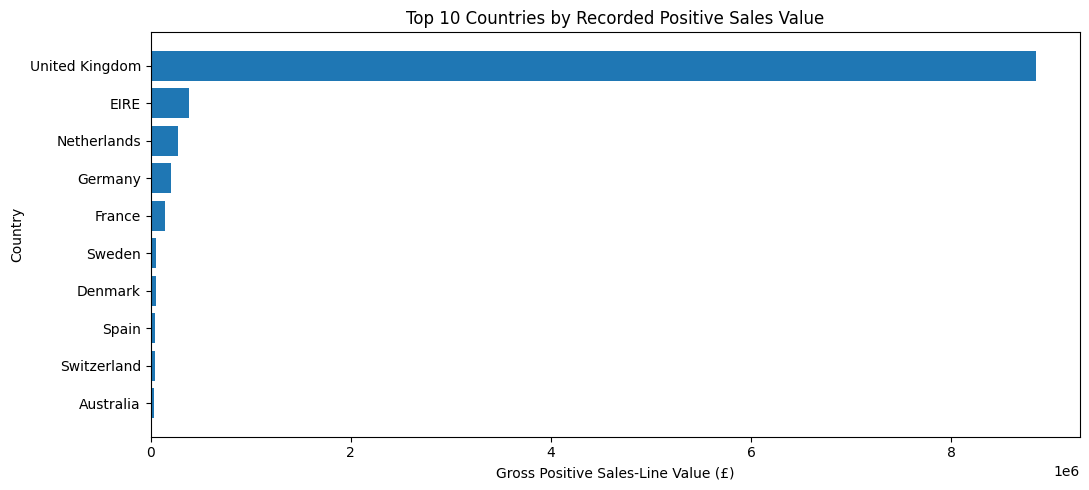


3. UK VS NON-UK SALES


,Region,Gross_Positive_Value,Share_%
0,United Kingdom,8845755.69,85.83
1,Other Countries,1460136.33,14.17



4. COUNTRIES WITH HIGHEST VALUE PER INVOICE


,Country,Transaction_Lines,Unique_Invoices,Unique_Customers,Gross_Positive_Value,Value_Per_Invoice,Sales_Share_%
24,Netherlands,2729,135,22,268786.00,1991.01,2.61
9,Denmark,418,26,9,50906.85,1957.96,0.49
33,Switzerland,1170,40,14,43921.39,1098.03,0.43
10,EIRE,9459,348,5,380977.82,1094.76,3.70
7,Channel Islands,821,30,11,24546.32,818.21,0.24
0,Australia,630,40,15,31446.80,786.17,0.31
32,Sweden,887,69,16,53525.39,775.73,0.52
31,Spain,1235,66,25,47601.42,721.23,0.46
12,France,5532,241,47,147211.49,610.84,1.43
28,Portugal,1061,41,18,24269.55,591.94,0.24


In [16]:

import pandas as pd
import matplotlib.pyplot as plt

# Use the temporary positive-sales view from Step 6
country_eda = monthly_eda.copy()

# Country-wise analysis
country_summary = (
    country_eda.groupby("Country")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Unique_Customers=("Customer ID", "nunique"),
        Gross_Positive_Value=("Line_Value", "sum")
    )
    .reset_index()
)

# Calculate average positive sales value per invoice
country_summary["Value_Per_Invoice"] = (
    country_summary["Gross_Positive_Value"] /
    country_summary["Unique_Invoices"]
)

# Calculate each country's share
total_value = country_summary["Gross_Positive_Value"].sum()

country_summary["Sales_Share_%"] = (
    country_summary["Gross_Positive_Value"] /
    total_value * 100
)

# Sort from highest to lowest
country_summary = country_summary.sort_values(
    "Gross_Positive_Value",
    ascending=False
)

print("1. TOP 15 COUNTRIES BY SALES VALUE")

display(country_summary.head(15).round(2))

print("\n2. TOP 10 COUNTRIES - SALES CHART")

top10 = country_summary.head(10)

plt.figure(figsize=(11, 5))
plt.barh(
    top10["Country"][::-1],
    top10["Gross_Positive_Value"][::-1]
)

plt.xlabel("Gross Positive Sales-Line Value (£)")
plt.ylabel("Country")
plt.title("Top 10 Countries by Recorded Positive Sales Value")
plt.tight_layout()
plt.show()

print("\n3. UK VS NON-UK SALES")

uk_value = country_eda.loc[
    country_eda["Country"] == "United Kingdom",
    "Line_Value"
].sum()

non_uk_value = total_value - uk_value

display(pd.DataFrame({
    "Region": ["United Kingdom", "Other Countries"],
    "Gross_Positive_Value": [uk_value, non_uk_value],
    "Share_%": [
        uk_value / total_value * 100,
        non_uk_value / total_value * 100
    ]
}).round(2))

print("\n4. COUNTRIES WITH HIGHEST VALUE PER INVOICE")

display(
    country_summary[
        country_summary["Unique_Invoices"] >= 20
    ]
    .nlargest(10, "Value_Per_Invoice")
    .round(2)
)


1. TOP 15 PRODUCTS BY QUANTITY SOLD


,StockCode,Description,Total_Units,Gross_Positive_Value,Transaction_Lines,Unique_Invoices,Unique_Customers
489,21212,PACK OF 72 RETRO SPOT CAKE CASES,60141,31738.10,1920,1853,771
3796,85123A,WHITE HANGING HEART T-LIGHT HOLDER,58487,158590.87,3421,3281,1141
2332,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55091,11418.05,506,501,282
3781,85099B,JUMBO BAG RED WHITE SPOTTY,49875,89114.78,2012,1966,692
50,17003,BROCADE RING PURSE,48374,8922.80,234,230,127
2501,84879,ASSORTED COLOUR BIRD ORNAMENT,45348,73092.99,1449,1412,627
2542,84991,60 TEATIME FAIRY CAKE CASES,36502,18220.50,1394,1336,600
1306,22197,"POPCORN HOLDER , SMALL",32977,29566.62,1020,994,346
1120,21977,PACK OF 60 PINK PAISLEY CAKE CASES,31940,16245.96,1191,1155,518
506,21232,STRAWBERRY CERAMIC TRINKET BOX,27127,34496.68,1713,1640,555



2. TOP 15 PRODUCTS BY SALES VALUE


,StockCode,Description,Total_Units,Gross_Positive_Value,Transaction_Lines,Unique_Invoices,Unique_Customers
4236,M,Manual,2826,262606.01,555,512,283
1511,22423,REGENCY CAKESTAND 3 TIER,13698,170078.51,2044,2019,818
3796,85123A,WHITE HANGING HEART T-LIGHT HOLDER,58487,158590.87,3421,3281,1141
4235,DOT,DOTCOM POSTAGE,730,116408.71,730,730,0
3781,85099B,JUMBO BAG RED WHITE SPOTTY,49875,89114.78,2012,1966,692
2501,84879,ASSORTED COLOUR BIRD ORNAMENT,45348,73092.99,1449,1412,627
1199,22086,PAPER CHAIN KIT 50'S CHRISTMAS,17226,58189.25,998,957,505
2186,47566,PARTY BUNTING,10083,49682.72,1034,1013,391
4238,POST,POSTAGE,2310,49477.54,759,759,230
2348,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,23049,47985.09,365,347,177



3. TOP 15 PRODUCTS BY CUSTOMER REACH


,StockCode,Description,Total_Units,Gross_Positive_Value,Transaction_Lines,Unique_Invoices,Unique_Customers
3796,85123A,WHITE HANGING HEART T-LIGHT HOLDER,58487,158590.87,3421,3281,1141
1511,22423,REGENCY CAKESTAND 3 TIER,13698,170078.51,2044,2019,818
489,21212,PACK OF 72 RETRO SPOT CAKE CASES,60141,31738.10,1920,1853,771
3781,85099B,JUMBO BAG RED WHITE SPOTTY,49875,89114.78,2012,1966,692
1250,22138,BAKING SET 9 PIECE RETROSPOT,4435,21726.44,992,980,632
2501,84879,ASSORTED COLOUR BIRD ORNAMENT,45348,73092.99,1449,1412,627
1251,22139,RETRO SPOT TEA SET CERAMIC 11 PC,6148,30301.50,1158,1138,619
2542,84991,60 TEATIME FAIRY CAKE CASES,36502,18220.50,1394,1336,600
132,20725,LUNCH BAG RED SPOTTY,21389,36250.84,1584,1539,582
1555,22470,HEART OF WICKER LARGE,8650,25759.46,1141,1092,570


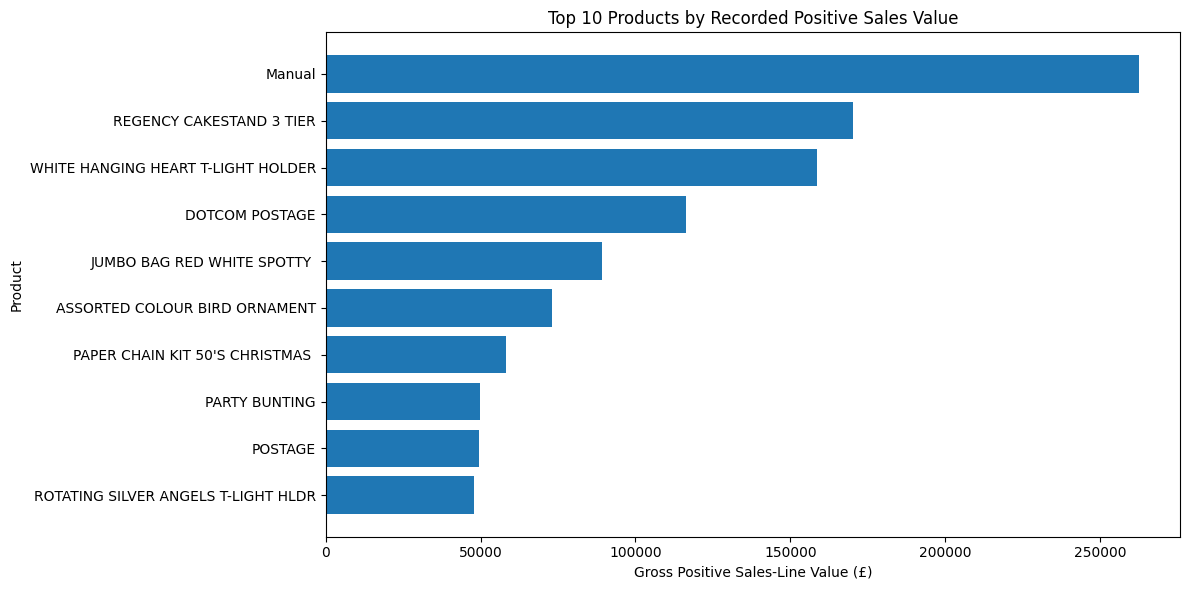


4. PRODUCT DESCRIPTION CONSISTENCY
Stock codes with multiple descriptions: 449
Stock codes with no non-missing description: 0


In [17]:

import pandas as pd
import matplotlib.pyplot as plt

# Temporary EDA view, not permanent preprocessing
product_eda = monthly_eda.copy()

# Group by product identifier
product_summary = (
    product_eda.groupby("StockCode", dropna=False)
    .agg(
        Description=("Description", "first"),
        Total_Units=("Quantity", "sum"),
        Gross_Positive_Value=("Line_Value", "sum"),
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

print("1. TOP 15 PRODUCTS BY QUANTITY SOLD")

display(
    product_summary.nlargest(
        15, "Total_Units"
    ).round(2)
)

print("\n2. TOP 15 PRODUCTS BY SALES VALUE")

display(
    product_summary.nlargest(
        15, "Gross_Positive_Value"
    ).round(2)
)

print("\n3. TOP 15 PRODUCTS BY CUSTOMER REACH")

display(
    product_summary.nlargest(
        15, "Unique_Customers"
    ).round(2)
)

# Visualize top products by sales value
top_products = product_summary.nlargest(
    10, "Gross_Positive_Value"
).copy()

top_products["Product"] = (
    top_products["Description"]
    .fillna(top_products["StockCode"].astype(str))
    .str.slice(0, 35)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["Product"][::-1],
    top_products["Gross_Positive_Value"][::-1]
)

plt.xlabel("Gross Positive Sales-Line Value (£)")
plt.ylabel("Product")
plt.title("Top 10 Products by Recorded Positive Sales Value")
plt.tight_layout()
plt.show()

print("\n4. PRODUCT DESCRIPTION CONSISTENCY")

description_counts = (
    product_eda.groupby("StockCode")["Description"]
    .nunique(dropna=True)
)

print(
    "Stock codes with multiple descriptions:",
    (description_counts > 1).sum()
)

print(
    "Stock codes with no non-missing description:",
    (description_counts == 0).sum()
)


1. CUSTOMER PURCHASE FREQUENCY STATISTICS


,Purchase_Frequency
count,4312.000000
mean,4.455705
std,8.170213
min,1.000000
25%,1.000000
50%,2.000000
75%,5.000000
90%,9.000000
95%,13.000000
99%,31.000000



2. ONE-TIME VS REPEAT CUSTOMERS


,Customer Type,Customers,Percentage
0,One-time customers,1419,32.91
1,Repeat customers,2893,67.09



3. PURCHASE FREQUENCY DISTRIBUTION


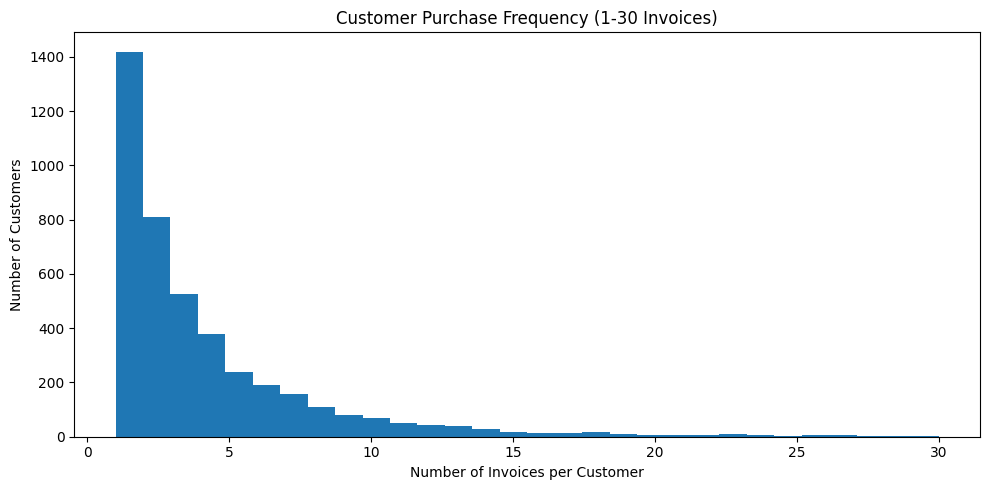


4. TOP 10 MOST FREQUENT CUSTOMERS


,Customer ID,Purchase_Frequency
1840,14911.0,205
3996,17850.0,155
251,12748.0,144
2133,15311.0,121
506,13089.0,109
1269,14156.0,102
1606,14606.0,102
939,13694.0,94
3989,17841.0,91
4183,18102.0,89



5. CUSTOMERS BY PURCHASE FREQUENCY


,Purchase Range,Customers
0,1 purchase,1419
1,2-5 purchases,1951
2,6-10 purchases,607
3,11-20 purchases,242
4,More than 20 purchases,93


In [18]:

import pandas as pd
import matplotlib.pyplot as plt

# Temporary customer EDA view
customer_eda = monthly_eda.loc[
    monthly_eda["Customer ID"].notna()
].copy()

# Count unique invoices per customer
customer_frequency = (
    customer_eda.groupby("Customer ID")["Invoice"]
    .nunique()
    .rename("Purchase_Frequency")
    .reset_index()
)

print("1. CUSTOMER PURCHASE FREQUENCY STATISTICS")

display(
    customer_frequency["Purchase_Frequency"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

# One-time vs repeat customers
one_time = (
    customer_frequency["Purchase_Frequency"] == 1
).sum()

repeat = (
    customer_frequency["Purchase_Frequency"] > 1
).sum()

total = len(customer_frequency)

print("\n2. ONE-TIME VS REPEAT CUSTOMERS")

display(pd.DataFrame({
    "Customer Type": [
        "One-time customers",
        "Repeat customers"
    ],
    "Customers": [one_time, repeat],
    "Percentage": [
        round(one_time / total * 100, 2),
        round(repeat / total * 100, 2)
    ]
}))

print("\n3. PURCHASE FREQUENCY DISTRIBUTION")

plt.figure(figsize=(10, 5))

plt.hist(
    customer_frequency.loc[
        customer_frequency["Purchase_Frequency"] <= 30,
        "Purchase_Frequency"
    ],
    bins=30
)

plt.title("Customer Purchase Frequency (1-30 Invoices)")
plt.xlabel("Number of Invoices per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("\n4. TOP 10 MOST FREQUENT CUSTOMERS")

display(
    customer_frequency.nlargest(
        10, "Purchase_Frequency"
    )
)

print("\n5. CUSTOMERS BY PURCHASE FREQUENCY")

display(
    pd.DataFrame({
        "Purchase Range": [
            "1 purchase",
            "2-5 purchases",
            "6-10 purchases",
            "11-20 purchases",
            "More than 20 purchases"
        ],
        "Customers": [
            (customer_frequency["Purchase_Frequency"] == 1).sum(),
            customer_frequency["Purchase_Frequency"].between(2, 5).sum(),
            customer_frequency["Purchase_Frequency"].between(6, 10).sum(),
            customer_frequency["Purchase_Frequency"].between(11, 20).sum(),
            (customer_frequency["Purchase_Frequency"] > 20).sum()
        ]
    })
)


1. CUSTOMER SPENDING STATISTICS


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Total_Spending,4312.0,2048.24,8914.48,2.95,307.99,706.02,1723.14,3800.23,6237.60,20137.24,349164.35
Avg_Invoice_Value,4312.0,378.32,492.56,2.95,182.09,287.37,423.58,670.80,920.83,1954.55,11880.84



2. TOP 10 HIGHEST-SPENDING CUSTOMERS


,Customer ID,Total_Spending,Total_Invoices,Total_Units,Avg_Invoice_Value
4183,18102.0,349164.35,89,124216,3923.19
1637,14646.0,248396.50,78,170278,3184.57
1269,14156.0,196566.74,102,108107,1927.12
1840,14911.0,152147.57,205,69722,742.18
939,13694.0,131443.19,94,125893,1398.33
3744,17511.0,84541.17,31,55107,2727.13
1951,15061.0,83284.38,86,51791,968.42
3128,16684.0,80489.21,27,54555,2981.08
3177,16754.0,65500.07,29,63551,2258.62
4065,17949.0,60117.60,74,30112,812.40



3. SPENDING DISTRIBUTION


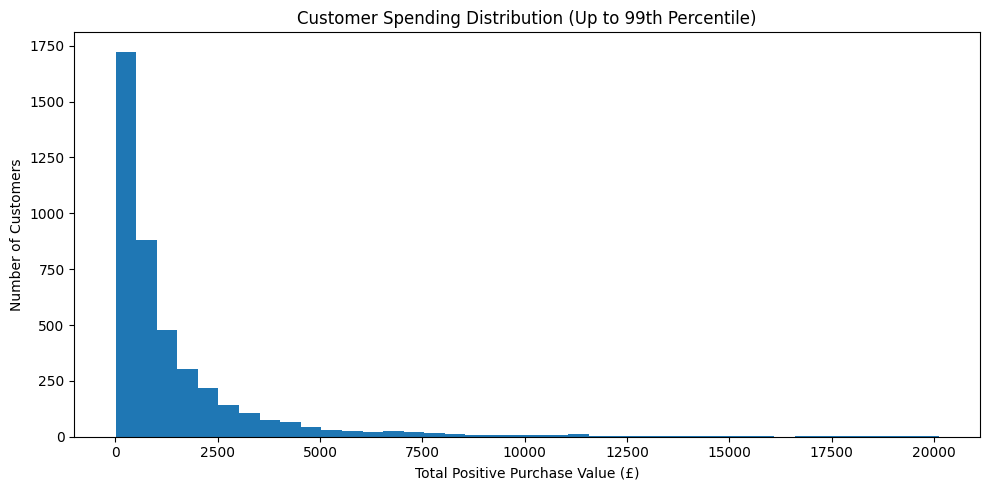


4. SALES VALUE CONCENTRATION


,Top Customer %,Customers,Share of Identified Sales %
0,1,44,28.72
1,5,216,48.31
2,10,432,59.87
3,20,863,73.48



5. PURCHASE FREQUENCY VS SPENDING
Correlation: 0.6563


In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Start from temporary EDA data with identified customers
spending_eda = customer_eda.copy()

# Calculate total positive spending per customer
customer_spending = (
    spending_eda.groupby("Customer ID")
    .agg(
        Total_Spending=("Line_Value", "sum"),
        Total_Invoices=("Invoice", "nunique"),
        Total_Units=("Quantity", "sum")
    )
    .reset_index()
)

# Average positive value per invoice
customer_spending["Avg_Invoice_Value"] = (
    customer_spending["Total_Spending"] /
    customer_spending["Total_Invoices"]
)

print("1. CUSTOMER SPENDING STATISTICS")

display(
    customer_spending[
        ["Total_Spending", "Avg_Invoice_Value"]
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).T.round(2)
)

print("\n2. TOP 10 HIGHEST-SPENDING CUSTOMERS")

display(
    customer_spending.nlargest(
        10, "Total_Spending"
    ).round(2)
)

print("\n3. SPENDING DISTRIBUTION")

# Display typical customers without allowing extreme
# spending values to obscure the distribution.
plot_limit = customer_spending[
    "Total_Spending"
].quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    customer_spending.loc[
        customer_spending["Total_Spending"] <= plot_limit,
        "Total_Spending"
    ],
    bins=40
)

plt.title("Customer Spending Distribution (Up to 99th Percentile)")
plt.xlabel("Total Positive Purchase Value (£)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("\n4. SALES VALUE CONCENTRATION")

sorted_spending = customer_spending.sort_values(
    "Total_Spending",
    ascending=False
)

total_spending = sorted_spending[
    "Total_Spending"
].sum()

concentration = []

for percentage in [1, 5, 10, 20]:
    n_customers = max(
        1,
        int(np.ceil(
            len(sorted_spending) * percentage / 100
        ))
    )

    top_value = sorted_spending.head(
        n_customers
    )["Total_Spending"].sum()

    concentration.append({
        "Top Customer %": percentage,
        "Customers": n_customers,
        "Share of Identified Sales %": round(
            top_value / total_spending * 100,
            2
        )
    })

display(pd.DataFrame(concentration))

print("\n5. PURCHASE FREQUENCY VS SPENDING")

print(
    "Correlation:",
    round(
        customer_spending[
            ["Total_Invoices", "Total_Spending"]
        ].corr().iloc[0, 1],
        4
    )
)


REFERENCE DATE: 2010-12-10 20:01:00

1. CUSTOMER RECENCY STATISTICS


,Recency_Days
count,4312.00
mean,91.45
std,96.86
min,1.00
25%,18.37
50%,53.14
75%,136.42
90%,255.12
95%,304.33
max,374.42



2. PURCHASE GAP STATISTICS


,Avg_Purchase_Gap_Days
count,2893.00
mean,70.13
std,62.10
min,0.00
25%,28.44
50%,51.99
75%,89.95
90%,152.98
95%,195.94
max,361.84



3. RECENCY DISTRIBUTION


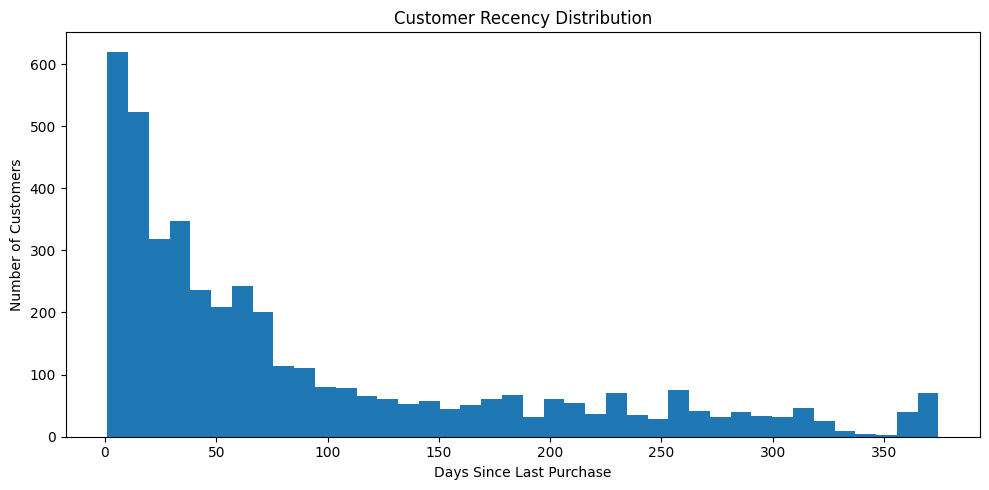


4. CUSTOMERS BY RECENCY RANGE


,Customers
Recency_Group,
0-30 days,1513
31-60 days,842
61-90 days,522
91-180 days,604
Over 180 days,831



5. SAMPLE CUSTOMER BEHAVIOR


,Customer ID,Purchase_Frequency,Recency_Days,Avg_Purchase_Gap_Days
0,12346.0,11,165.26,19.62
1,12347.0,2,3.21,37.03
2,12348.0,1,74.21,NaN
3,12349.0,3,43.48,90.90
4,12351.0,1,11.19,NaN
5,12352.0,2,11.41,16.99
6,12353.0,1,44.30,NaN
7,12355.0,1,203.33,NaN
8,12356.0,3,16.32,22.06
9,12357.0,2,24.23,0.18


In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Use identified customers and positive sales
recency_eda = customer_eda.copy()

# Ensure invoice dates are datetime
recency_eda["InvoiceDate"] = pd.to_datetime(
    recency_eda["InvoiceDate"]
)

# Reference date: day after last transaction
reference_date = (
    recency_eda["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

print("REFERENCE DATE:", reference_date)

# Customer-level purchase dates
customer_dates = (
    recency_eda.groupby("Customer ID")
    .agg(
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max"),
        Purchase_Frequency=("Invoice", "nunique")
    )
    .reset_index()
)

# Calculate recency
customer_dates["Recency_Days"] = (
    reference_date - customer_dates["Last_Purchase"]
).dt.total_seconds() / 86400

print("\n1. CUSTOMER RECENCY STATISTICS")

display(
    customer_dates["Recency_Days"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    ).to_frame()
    .round(2)
)

# One timestamp per customer and invoice
invoice_dates = (
    recency_eda.groupby(
        ["Customer ID", "Invoice"],
        as_index=False
    )["InvoiceDate"]
    .min()
)

invoice_dates = invoice_dates.sort_values(
    ["Customer ID", "InvoiceDate"]
)

# Time between purchases
invoice_dates["Purchase_Gap_Days"] = (
    invoice_dates.groupby("Customer ID")[
        "InvoiceDate"
    ].diff().dt.total_seconds() / 86400
)

# Customer-level average purchase gap
avg_gaps = (
    invoice_dates.groupby("Customer ID")[
        "Purchase_Gap_Days"
    ].mean()
    .rename("Avg_Purchase_Gap_Days")
    .reset_index()
)

customer_dates = customer_dates.merge(
    avg_gaps,
    on="Customer ID",
    how="left"
)

print("\n2. PURCHASE GAP STATISTICS")

display(
    customer_dates["Avg_Purchase_Gap_Days"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    ).to_frame()
    .round(2)
)

print("\n3. RECENCY DISTRIBUTION")

plt.figure(figsize=(10, 5))
plt.hist(
    customer_dates["Recency_Days"],
    bins=40
)
plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("\n4. CUSTOMERS BY RECENCY RANGE")

customer_dates["Recency_Group"] = pd.cut(
    customer_dates["Recency_Days"],
    bins=[0, 30, 60, 90, 180, float("inf")],
    labels=[
        "0-30 days",
        "31-60 days",
        "61-90 days",
        "91-180 days",
        "Over 180 days"
    ],
    include_lowest=True
)

display(
    customer_dates["Recency_Group"]
    .value_counts()
    .sort_index()
    .to_frame("Customers")
)

print("\n5. SAMPLE CUSTOMER BEHAVIOR")

display(
    customer_dates[
        [
            "Customer ID",
            "Purchase_Frequency",
            "Recency_Days",
            "Avg_Purchase_Gap_Days"
        ]
    ].head(10).round(2)
)


1. MONTHLY CUSTOMER ACTIVITY


,Month,Active_Customers,Unique_Invoices,Positive_Sales_Value
0,2009-12,955,1512,686654.16
1,2010-01,720,1011,557319.06
2,2010-02,772,1104,506371.07
3,2010-03,1057,1524,699608.99
4,2010-04,942,1329,594609.19
5,2010-05,966,1377,599985.79
6,2010-06,1041,1497,639066.58
7,2010-07,928,1381,591636.74
8,2010-08,911,1293,604242.65
9,2010-09,1145,1689,831615.00


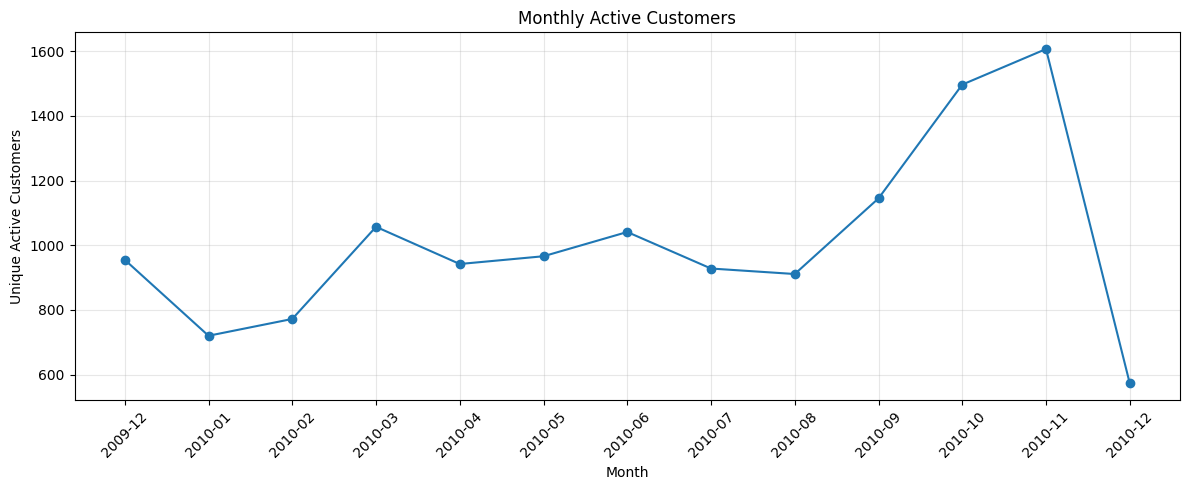


2. ACTIVE MONTHS PER CUSTOMER


,Active_Months
count,4312.00
mean,3.04
std,2.59
min,1.00
25%,1.00
50%,2.00
75%,4.00
90%,7.00
95%,9.00
max,13.00



3. CUSTOMER ACTIVITY GROUPS


,Customers
Active_Months,
1 month,1591
2-3 months,1448
4-6 months,795
7-9 months,316
10-13 months,162



4. CUSTOMER ACTIVITY EXAMPLES


,Active_Months
Customer ID,
12682.0,13
12748.0,13
12921.0,13
13078.0,13
13089.0,13
13093.0,13
13199.0,13
13408.0,13
13468.0,13


In [21]:

import pandas as pd
import matplotlib.pyplot as plt

# Use positive sales with identified customers
activity_eda = customer_eda.copy()

# Create monthly period for temporary analysis
activity_eda["Month"] = (
    activity_eda["InvoiceDate"].dt.to_period("M")
)

# One customer counted once per month
monthly_active = (
    activity_eda.groupby("Month")
    .agg(
        Active_Customers=("Customer ID", "nunique"),
        Unique_Invoices=("Invoice", "nunique"),
        Positive_Sales_Value=("Line_Value", "sum")
    )
    .reset_index()
)

monthly_active["Month"] = monthly_active["Month"].astype(str)

print("1. MONTHLY CUSTOMER ACTIVITY")
display(monthly_active.round(2))

# Chart monthly active customers
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_active["Month"],
    monthly_active["Active_Customers"],
    marker="o"
)
plt.title("Monthly Active Customers")
plt.xlabel("Month")
plt.ylabel("Unique Active Customers")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Count the number of distinct months each customer purchased
customer_active_months = (
    activity_eda.groupby("Customer ID")["Month"]
    .nunique()
    .rename("Active_Months")
)

print("\n2. ACTIVE MONTHS PER CUSTOMER")
display(
    customer_active_months.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    ).to_frame().round(2)
)

print("\n3. CUSTOMER ACTIVITY GROUPS")

activity_groups = pd.cut(
    customer_active_months,
    bins=[0, 1, 3, 6, 9, 13],
    labels=[
        "1 month",
        "2-3 months",
        "4-6 months",
        "7-9 months",
        "10-13 months"
    ]
)

display(
    activity_groups.value_counts()
    .sort_index()
    .to_frame("Customers")
)

print("\n4. CUSTOMER ACTIVITY EXAMPLES")

display(
    customer_active_months.nlargest(10)
    .to_frame()
)


1. CUSTOMER COHORT SIZES


,Customers
Cohort_Month,
2009-12,955.0
2010-01,383.0
2010-02,374.0
2010-03,443.0
2010-04,294.0
2010-05,254.0
2010-06,270.0
2010-07,186.0
2010-08,162.0



2. COHORT RETENTION MATRIX (%)


Cohort_Index,0,1,2,3,4,5,6,7,8,9,10,11,12
Cohort_Month,,,,,,,,,,,,,
2009-12,100.0,35.3,33.4,42.5,38.0,35.9,37.7,34.2,33.6,36.2,42.2,49.5,24.8
2010-01,100.0,20.6,31.1,30.5,26.4,30.0,25.8,23.0,27.9,31.9,30.3,9.9,NaN
2010-02,100.0,23.8,22.5,29.1,24.6,20.1,19.3,28.6,25.4,27.5,7.2,NaN,NaN
2010-03,100.0,19.0,23.0,24.2,23.3,20.3,24.6,30.2,27.5,7.9,NaN,NaN,NaN
2010-04,100.0,19.4,19.4,16.3,18.4,22.4,27.6,26.2,6.8,NaN,NaN,NaN,NaN
2010-05,100.0,15.7,16.9,17.3,17.7,25.6,21.3,7.9,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.4,18.9,20.4,23.0,28.5,6.7,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.6,18.3,29.6,29.0,10.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.4,29.6,32.1,11.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


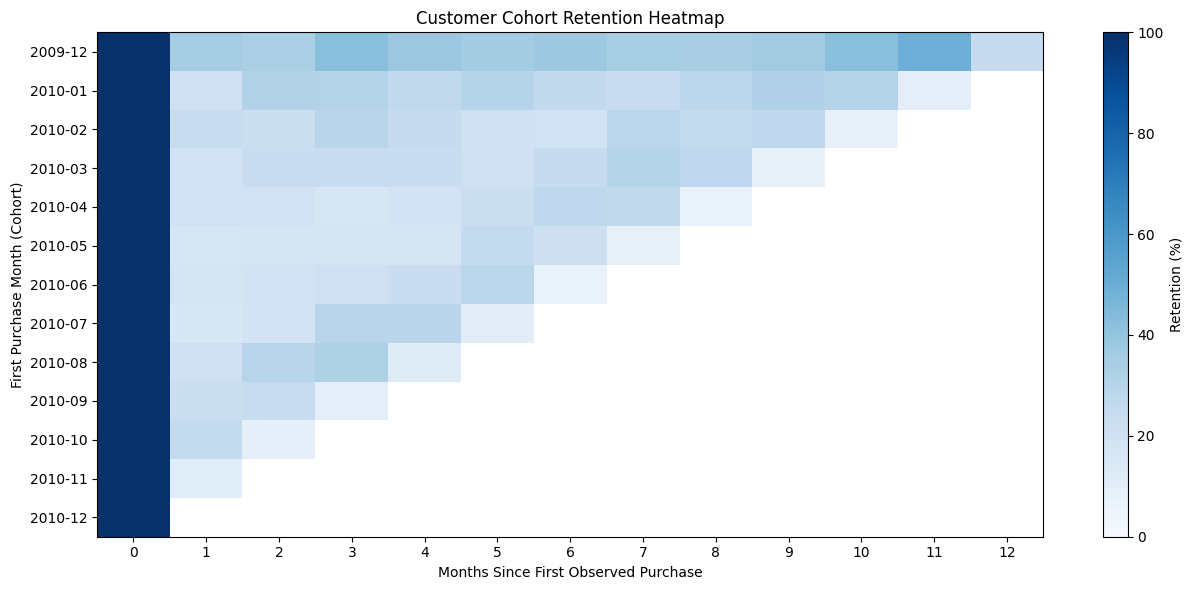


3. RETENTION IN MONTH 1


,Month 1 Retention (%)
Cohort_Month,
2009-12,35.29
2010-01,20.63
2010-02,23.80
2010-03,18.96
2010-04,19.39
2010-05,15.75
2010-06,17.41
2010-07,15.59
2010-08,20.37


In [22]:

import pandas as pd
import matplotlib.pyplot as plt

# Use temporary positive-sales data with known customers
cohort_eda = customer_eda.copy()

# Get each transaction's calendar month
cohort_eda["Order_Month"] = (
    cohort_eda["InvoiceDate"]
    .dt.to_period("M")
)

# Find each customer's first observed purchase month
cohort_eda["Cohort_Month"] = (
    cohort_eda.groupby("Customer ID")["Order_Month"]
    .transform("min")
)

# Calculate months since first observed purchase
cohort_eda["Cohort_Index"] = (
    (cohort_eda["Order_Month"].dt.year -
     cohort_eda["Cohort_Month"].dt.year) * 12
    +
    (cohort_eda["Order_Month"].dt.month -
     cohort_eda["Cohort_Month"].dt.month)
)

# Count unique active customers by cohort and month
cohort_counts = (
    cohort_eda.groupby(
        ["Cohort_Month", "Cohort_Index"]
    )["Customer ID"]
    .nunique()
    .unstack()
)

# Calculate retention percentage
cohort_sizes = cohort_counts[0]

cohort_retention = (
    cohort_counts.div(cohort_sizes, axis=0) * 100
)

print("1. CUSTOMER COHORT SIZES")
display(
    cohort_sizes.to_frame("Customers")
)

print("\n2. COHORT RETENTION MATRIX (%)")
display(
    cohort_retention.round(1)
)

# Heatmap: standard Matplotlib, no extra packages
plt.figure(figsize=(13, 6))

masked_values = cohort_retention.to_numpy(
    dtype=float
)

plt.imshow(
    masked_values,
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Retention (%)")

plt.yticks(
    range(len(cohort_retention.index)),
    cohort_retention.index.astype(str)
)

plt.xticks(
    range(len(cohort_retention.columns)),
    cohort_retention.columns
)

plt.xlabel("Months Since First Observed Purchase")
plt.ylabel("First Purchase Month (Cohort)")
plt.title("Customer Cohort Retention Heatmap")

plt.tight_layout()
plt.show()

print("\n3. RETENTION IN MONTH 1")

if 1 in cohort_retention.columns:
    display(
        cohort_retention[1]
        .dropna()
        .round(2)
        .to_frame("Month 1 Retention (%)")
    )


In [23]:

import pandas as pd

# Load second-year data
retail_df_year2 = pd.read_excel(
    excel_path,
    sheet_name="Year 2010-2011"
)

print("SECOND YEAR LOADED SUCCESSFULLY!")

print("\n1. DATASET SHAPE")
print(retail_df_year2.shape)

print("\n2. COLUMN NAMES")
print(retail_df_year2.columns.tolist())

print("\n3. FIRST 5 RECORDS")
display(retail_df_year2.head())

print("\n4. MISSING VALUES")
display(
    pd.DataFrame({
        "Missing Count": retail_df_year2.isna().sum(),
        "Missing %": (
            retail_df_year2.isna().mean() * 100
        ).round(2)
    })
)

print("\n5. TRANSACTION DATE RANGE")
print(
    "Earliest:",
    retail_df_year2["InvoiceDate"].min()
)
print(
    "Latest:",
    retail_df_year2["InvoiceDate"].max()
)

print("\n6. UNIQUE CUSTOMERS AND INVOICES")
print(
    "Unique customers:",
    retail_df_year2["Customer ID"].nunique()
)
print(
    "Unique invoices:",
    retail_df_year2["Invoice"].nunique()
)

print("\n7. DUPLICATE AND UNUSUAL RECORDS")
print(
    "Exact duplicates:",
    retail_df_year2.duplicated().sum()
)
print(
    "Negative quantities:",
    (retail_df_year2["Quantity"] < 0).sum()
)
print(
    "Zero prices:",
    (retail_df_year2["Price"] == 0).sum()
)
print(
    "Negative prices:",
    (retail_df_year2["Price"] < 0).sum()
)


SECOND YEAR LOADED SUCCESSFULLY!

1. DATASET SHAPE
(541910, 8)

2. COLUMN NAMES
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

3. FIRST 5 RECORDS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



4. MISSING VALUES


,Missing Count,Missing %
Invoice,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,135080,24.93
Country,0,0.00



5. TRANSACTION DATE RANGE
Earliest: 2010-12-01 08:26:00
Latest: 2011-12-09 12:50:00

6. UNIQUE CUSTOMERS AND INVOICES
Unique customers: 4372
Unique invoices: 25900

7. DUPLICATE AND UNUSUAL RECORDS
Exact duplicates: 5268
Negative quantities: 10624
Zero prices: 2515
Negative prices: 2


In [24]:

import pandas as pd

# Work with raw copies
year1 = retail_df.copy()
year2 = retail_df_year2.copy()

print("1. CUSTOMER OVERLAP BETWEEN YEARS")

customers_y1 = set(
    year1["Customer ID"].dropna()
)

customers_y2 = set(
    year2["Customer ID"].dropna()
)

common_customers = customers_y1 & customers_y2

display(pd.DataFrame({
    "Metric": [
        "Customers in Year 1",
        "Customers in Year 2",
        "Customers in both years",
        "Only in Year 1",
        "Only in Year 2"
    ],
    "Count": [
        len(customers_y1),
        len(customers_y2),
        len(common_customers),
        len(customers_y1 - customers_y2),
        len(customers_y2 - customers_y1)
    ]
}))

print("\n2. INVOICE OVERLAP BETWEEN YEARS")

invoices_y1 = set(
    year1["Invoice"].astype(str).str.strip()
)

invoices_y2 = set(
    year2["Invoice"].astype(str).str.strip()
)

common_invoices = invoices_y1 & invoices_y2

print("Shared invoice identifiers:", len(common_invoices))

print("\n3. EXACT RECORD OVERLAP BETWEEN YEARS")

# Compare each unique complete row without modifying raw data
cols = year1.columns.tolist()

unique_y1 = year1[cols].drop_duplicates()
unique_y2 = year2[cols].drop_duplicates()

shared_rows = unique_y1.merge(
    unique_y2,
    on=cols,
    how="inner"
)

print(
    "Distinct complete records found in both sheets:",
    len(shared_rows)
)

print("\n4. DATE RANGE OVERLAP")

overlap_start = max(
    year1["InvoiceDate"].min(),
    year2["InvoiceDate"].min()
)

overlap_end = min(
    year1["InvoiceDate"].max(),
    year2["InvoiceDate"].max()
)

print("Overlap starts:", overlap_start)
print("Overlap ends:", overlap_end)

print("\nRecords during overlapping period:")

print(
    "Year 1:",
    year1["InvoiceDate"].between(
        overlap_start, overlap_end
    ).sum()
)

print(
    "Year 2:",
    year2["InvoiceDate"].between(
        overlap_start, overlap_end
    ).sum()
)

print("\n5. SAMPLE SHARED INVOICES")

print(
    sorted(common_invoices)[:15]
)

print("\n6. SAMPLE SHARED COMPLETE RECORDS")

display(shared_rows.head(10))


1. CUSTOMER OVERLAP BETWEEN YEARS


,Metric,Count
0,Customers in Year 1,4383
1,Customers in Year 2,4372
2,Customers in both years,2813
3,Only in Year 1,1570
4,Only in Year 2,1559



2. INVOICE OVERLAP BETWEEN YEARS
Shared invoice identifiers: 1088

3. EXACT RECORD OVERLAP BETWEEN YEARS
Distinct complete records found in both sheets: 22202

4. DATE RANGE OVERLAP
Overlap starts: 2010-12-01 08:26:00
Overlap ends: 2010-12-09 20:01:00

Records during overlapping period:
Year 1: 22523
Year 2: 22523

5. SAMPLE SHARED INVOICES
['536365', '536366', '536367', '536368', '536369', '536370', '536371', '536372', '536373', '536374', '536375', '536376', '536377', '536378', '536380']

6. SAMPLE SHARED COMPLETE RECORDS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536368,22960,JAM MAKING SET WITH JARS,6,2010-12-01 08:34:00,4.25,13047.0,United Kingdom


In [25]:

import pandas as pd

# Work with original raw data
y1 = retail_df.copy()
y2 = retail_df_year2.copy()

print("1. VERIFY OVERLAPPING TRANSACTIONS")

overlap_start = max(
    y1["InvoiceDate"].min(),
    y2["InvoiceDate"].min()
)

overlap_end = min(
    y1["InvoiceDate"].max(),
    y2["InvoiceDate"].max()
)

overlap_y1 = y1.loc[
    y1["InvoiceDate"].between(
        overlap_start, overlap_end
    )
].copy()

overlap_y2 = y2.loc[
    y2["InvoiceDate"].between(
        overlap_start, overlap_end
    )
].copy()

# Count identical rows, including repeated occurrences
columns = retail_df.columns.tolist()

counts_y1 = (
    overlap_y1.groupby(
        columns, dropna=False
    )
    .size()
    .rename("Year1_Count")
)

counts_y2 = (
    overlap_y2.groupby(
        columns, dropna=False
    )
    .size()
    .rename("Year2_Count")
)

overlap_comparison = pd.concat(
    [counts_y1, counts_y2],
    axis=1
).fillna(0)

matching = (
    overlap_comparison["Year1_Count"] ==
    overlap_comparison["Year2_Count"]
).all()

print("Overlapping periods identical:", matching)

print(
    "Different row groups:",
    (
        overlap_comparison["Year1_Count"] !=
        overlap_comparison["Year2_Count"]
    ).sum()
)

print("\n2. COMBINED CUSTOMER COVERAGE")

all_customers = (
    set(y1["Customer ID"].dropna()) |
    set(y2["Customer ID"].dropna())
)

print(
    "Total unique identified customers:",
    len(all_customers)
)

print("\n3. OVERLAP SIZE")

print("Year 1 overlap rows:", len(overlap_y1))
print("Year 2 overlap rows:", len(overlap_y2))

print("\n4. COMPLETE DATASET DATE RANGE")

print(
    "Earliest date:",
    min(
        y1["InvoiceDate"].min(),
        y2["InvoiceDate"].min()
    )
)

print(
    "Latest date:",
    max(
        y1["InvoiceDate"].max(),
        y2["InvoiceDate"].max()
    )
)

print("\n5. COMBINED RAW ROW COUNT")

print(
    "Rows before overlap handling:",
    len(y1) + len(y2)
)

if matching:
    print(
        "Rows after excluding the overlapping "
        "period from Year 1:",
        len(y1) + len(y2) - len(overlap_y1)
    )
else:
    print(
        "Overlap differs. Requires further "
        "investigation before combining."
    )


1. VERIFY OVERLAPPING TRANSACTIONS
Overlapping periods identical: True
Different row groups: 0

2. COMBINED CUSTOMER COVERAGE
Total unique identified customers: 5942

3. OVERLAP SIZE
Year 1 overlap rows: 22523
Year 2 overlap rows: 22523

4. COMPLETE DATASET DATE RANGE
Earliest date: 2009-12-01 07:45:00
Latest date: 2011-12-09 12:50:00

5. COMBINED RAW ROW COUNT
Rows before overlap handling: 1067371
Rows after excluding the overlapping period from Year 1: 1044848


In [26]:

import pandas as pd

# Preserve the original datasets
year1 = retail_df.copy()
year2 = retail_df_year2.copy()

# Convert dates to datetime
year1["InvoiceDate"] = pd.to_datetime(
    year1["InvoiceDate"]
)

year2["InvoiceDate"] = pd.to_datetime(
    year2["InvoiceDate"]
)

# Start of the second year's coverage
year2_start = year2["InvoiceDate"].min()

# Keep first-year transactions before second year begins
year1_nonoverlap = year1.loc[
    year1["InvoiceDate"] < year2_start
].copy()

# Combine both datasets
combined_df = pd.concat(
    [year1_nonoverlap, year2],
    ignore_index=True
)

print("DATASETS COMBINED SUCCESSFULLY!")

print("\n1. COMBINATION SUMMARY")

summary = pd.DataFrame({
    "Dataset": [
        "Original Year 1",
        "Year 1 without overlap",
        "Complete Year 2",
        "Final Combined Dataset"
    ],
    "Records": [
        len(year1),
        len(year1_nonoverlap),
        len(year2),
        len(combined_df)
    ]
})

display(summary)

print("\n2. DATE RANGE")

print(
    "Earliest:",
    combined_df["InvoiceDate"].min()
)

print(
    "Latest:",
    combined_df["InvoiceDate"].max()
)

print("\n3. UNIQUE CUSTOMERS")

print(
    combined_df["Customer ID"].nunique()
)

print("\n4. MISSING VALUES")

display(
    pd.DataFrame({
        "Missing Count": combined_df.isna().sum(),
        "Missing %": (
            combined_df.isna().mean() * 100
        ).round(2)
    })
)

print("\n5. EXACT DUPLICATE ROWS REMAINING")

print(
    combined_df.duplicated().sum()
)

print("\n6. COMBINATION VERIFICATION")

expected_rows = (
    len(year1_nonoverlap) + len(year2)
)

assert len(combined_df) == expected_rows
assert len(combined_df) == 1044848

print("Combined row count verified successfully!")


DATASETS COMBINED SUCCESSFULLY!

1. COMBINATION SUMMARY


,Dataset,Records
0,Original Year 1,525461
1,Year 1 without overlap,502938
2,Complete Year 2,541910
3,Final Combined Dataset,1044848



2. DATE RANGE
Earliest: 2009-12-01 07:45:00
Latest: 2011-12-09 12:50:00

3. UNIQUE CUSTOMERS
5942

4. MISSING VALUES


,Missing Count,Missing %
Invoice,0,0.00
StockCode,0,0.00
Description,4275,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,235287,22.52
Country,0,0.00



5. EXACT DUPLICATE ROWS REMAINING
11812

6. COMBINATION VERIFICATION
Combined row count verified successfully!


In [27]:

import pandas as pd
import numpy as np

# Preserve combined raw dataset
classified_df = combined_df.copy()

# Standardize invoice text
classified_df["Invoice_Str"] = (
    classified_df["Invoice"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Identify cancellation invoices
is_cancellation = (
    classified_df["Invoice_Str"]
    .str.startswith("C")
)

# Create transaction categories
conditions = [
    classified_df["Price"] < 0,

    classified_df["Price"] == 0,

    is_cancellation,

    classified_df["Quantity"] < 0,

    (
        (classified_df["Quantity"] > 0) &
        (classified_df["Price"] > 0)
    )
]

categories = [
    "Negative Price Adjustment",
    "Zero Price Transaction",
    "Cancellation / Return",
    "Other Negative Quantity",
    "Positive Value Transaction"
]

classified_df["Transaction_Type"] = np.select(
    conditions,
    categories,
    default="Other / Review"
)

# Calculate signed transaction value
classified_df["Line_Value"] = (
    classified_df["Quantity"] *
    classified_df["Price"]
)

print("1. TRANSACTION CLASSIFICATION SUMMARY")

transaction_summary = (
    classified_df.groupby("Transaction_Type")
    .agg(
        Records=("Invoice", "size"),
        Total_Line_Value=("Line_Value", "sum"),
        Missing_Customers=(
            "Customer ID",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

transaction_summary["Percentage"] = (
    transaction_summary["Records"] /
    len(classified_df) * 100
)

display(
    transaction_summary.round(2)
)

print("\n2. TOTAL SIGNED LINE VALUE")

print(
    f"£{classified_df['Line_Value'].sum():,.2f}"
)

print("\n3. CUSTOMER ID AVAILABILITY BY TRANSACTION TYPE")

display(
    pd.crosstab(
        classified_df["Transaction_Type"],
        classified_df["Customer ID"].isna(),
        rownames=["Transaction Type"],
        colnames=["Customer ID Missing"]
    )
)

print("\n4. SAMPLE TRANSACTIONS REQUIRING REVIEW")

display(
    classified_df.loc[
        classified_df["Transaction_Type"] ==
        "Other / Review"
    ].head(10)
)

print("\n5. TRANSACTION TYPE COUNTS")

display(
    classified_df["Transaction_Type"]
    .value_counts()
    .to_frame("Records")
)


1. TRANSACTION CLASSIFICATION SUMMARY


,Transaction_Type,Records,Total_Line_Value,Missing_Customers,Percentage
0,Cancellation / Return,19165,-1465303.66,719,1.83
1,Negative Price Adjustment,5,-158676.14,5,0.00
2,Positive Value Transaction,1019654,20533741.92,228609,97.59
3,Zero Price Transaction,6024,0.00,5954,0.58



2. TOTAL SIGNED LINE VALUE
£18,909,762.12

3. CUSTOMER ID AVAILABILITY BY TRANSACTION TYPE


Customer ID Missing,False,True
Transaction Type,,
Cancellation / Return,18446,719
Negative Price Adjustment,0,5
Positive Value Transaction,791045,228609
Zero Price Transaction,70,5954



4. SAMPLE TRANSACTIONS REQUIRING REVIEW


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Invoice_Str,Transaction_Type,Line_Value



5. TRANSACTION TYPE COUNTS


,Records
Transaction_Type,
Positive Value Transaction,1019654
Cancellation / Return,19165
Zero Price Transaction,6024
Negative Price Adjustment,5


In [28]:

import pandas as pd

# Preserve our classified dataset
review_df = classified_df.copy()

# Focus on positive-value transactions
positive_df = review_df.loc[
    review_df["Transaction_Type"] == "Positive Value Transaction"
].copy()

# Standardize product codes and descriptions for inspection
positive_df["StockCode_Text"] = (
    positive_df["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

positive_df["Description_Text"] = (
    positive_df["Description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

# Identify possible non-merchandise descriptions
keywords = (
    r"POSTAGE|BANK CHARGES|AMAZON FEE|"
    r"MANUAL|DISCOUNT|CARRIAGE|"
    r"ADJUST|COMMISSION"
)

suspected_admin = (
    positive_df["Description_Text"]
    .str.contains(keywords, regex=True)
)

# Common administrative stock codes
admin_codes = [
    "M", "DOT", "POST", "D",
    "BANK CHARGES", "AMAZONFEE"
]

suspected_admin = (
    suspected_admin |
    positive_df["StockCode_Text"].isin(admin_codes)
)

positive_df["Suspected_Admin"] = suspected_admin

print("1. POSSIBLE ADMINISTRATIVE TRANSACTIONS")

display(pd.DataFrame({
    "Category": [
        "Possible administrative lines",
        "Other positive-value lines"
    ],
    "Records": [
        suspected_admin.sum(),
        (~suspected_admin).sum()
    ],
    "Positive_Line_Value": [
        positive_df.loc[
            suspected_admin, "Line_Value"
        ].sum(),
        positive_df.loc[
            ~suspected_admin, "Line_Value"
        ].sum()
    ]
}).round(2))

print("\n2. TOP SUSPECTED ADMINISTRATIVE STOCK CODES")

display(
    positive_df.loc[suspected_admin]
    .groupby(["StockCode_Text", "Description_Text"])
    .agg(
        Records=("Invoice", "size"),
        Total_Value=("Line_Value", "sum")
    )
    .sort_values("Total_Value", ascending=False)
    .head(20)
    .round(2)
)

print("\n3. MISSING DESCRIPTIONS AMONG POSITIVE TRANSACTIONS")

print(
    positive_df["Description"].isna().sum()
)

print("\n4. ADMINISTRATIVE LINES WITH KNOWN CUSTOMERS")

print(
    positive_df.loc[
        suspected_admin, "Customer ID"
    ].notna().sum()
)


1. POSSIBLE ADMINISTRATIVE TRANSACTIONS


,Category,Records,Positive_Line_Value
0,Possible administrative lines,4686,833722.41
1,Other positive-value lines,1014968,19700019.51



2. TOP SUSPECTED ADMINISTRATIVE STOCK CODES


Records  Total_Value
StockCode_Text Description_Text                                         
M              MANUAL                                   861    339629.94
DOT            DOTCOM POSTAGE                          1415    309854.11
POST           POSTAGE                                 1851    125682.42
AMAZONFEE      AMAZON FEE                                 3     20467.80
C2             CARRIAGE                                 267     13426.00
B              ADJUST BAD DEBT                            1     11062.06
ADJUST         ADJUSTMENT BY JOHN ON 26/01/2010 17       16      6563.50
               ADJUSTMENT BY JOHN ON 26/01/2010 16       20      2334.43
23444          NEXT DAY CARRIAGE                         79      1200.00
23099          FRENCH CARRIAGE LANTERN                   59       925.35
ADJUST2        ADJUSTMENT BY PETER ON JUN 25 2010         3       731.05
85168B         BLACK BAROQUE CARRIAGE CLOCK              53       662.12
BANK CHARGES   BANK CHARGES                              34       519.24
D              DISCOUNT                                   5       397.89
85168A         WHITE BAROQUE CARRIAGE CLOCK              15       218.90
21347          GOTHIC CARRIAGE LANTERN                    4        47.60


3. MISSING DESCRIPTIONS AMONG POSITIVE TRANSACTIONS
0

4. ADMINISTRATIVE LINES WITH KNOWN CUSTOMERS
3006


In [29]:

import os
import pandas as pd
from google.colab import files

# Folder for all preprocessing outputs
output_folder = "/content/Customer_Intelligence_Preprocessing"
os.makedirs(output_folder, exist_ok=True)

# Prepare Step 19 review dataset
step19_df = positive_df.copy()

# Files to export
export_files = {
    "step17_combined_retail_transactions.csv": combined_df,
    "step18_classified_retail_transactions.csv": classified_df,
    "step19_admin_transaction_review.csv": step19_df
}

print("SAVING PREPROCESSING DATASETS\n")

for filename, data in export_files.items():

    path = os.path.join(output_folder, filename)

    # Save without Pandas index
    data.to_csv(path, index=False)

    size_mb = os.path.getsize(path) / (1024 * 1024)

    print(f"Saved: {filename}")
    print(f"Rows: {len(data):,}")
    print(f"Size: {size_mb:.2f} MB\n")

print("ALL CSV FILES SAVED SUCCESSFULLY!")

# Create a single ZIP to avoid multiple large downloads
import zipfile

zip_path = "/content/customer_intelligence_steps17_19.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for filename in export_files:
        path = os.path.join(output_folder, filename)
        z.write(path, arcname=filename)

print("\nDOWNLOADING ZIP FILE...")
files.download(zip_path)


SAVING PREPROCESSING DATASETS

Saved: step17_combined_retail_transactions.csv
Rows: 1,044,848
Size: 88.56 MB

Saved: step18_classified_retail_transactions.csv
Rows: 1,044,848
Size: 129.54 MB

Saved: step19_admin_transaction_review.csv
Rows: 1,019,654
Size: 165.20 MB

ALL CSV FILES SAVED SUCCESSFULLY!

DOWNLOADING ZIP FILE...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:

import pandas as pd
import os
from google.colab import files

# Start from Step 19's positive-value dataset
merchandise_df = positive_df.copy()

print("Original positive-value rows:", len(merchandise_df))

# Standardize stock codes
merchandise_df["StockCode_Clean"] = (
    merchandise_df["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Explicit non-merchandise codes identified during EDA
non_merchandise_codes = [
    "M",
    "DOT",
    "POST",
    "AMAZONFEE",
    "BANK CHARGES",
    "D",
    "C2",
    "B",
    "ADJUST",
    "ADJUST2"
]

# Flag administrative entries
merchandise_df["Is_Non_Merchandise"] = (
    merchandise_df["StockCode_Clean"]
    .isin(non_merchandise_codes)
)

print("\n1. NON-MERCHANDISE REMOVAL SUMMARY")

display(
    merchandise_df.groupby("Is_Non_Merchandise")
    .agg(
        Records=("Invoice", "size"),
        Line_Value=("Line_Value", "sum")
    )
    .round(2)
)

# Keep merchandise transactions only
merchandise_df = merchandise_df.loc[
    ~merchandise_df["Is_Non_Merchandise"]
].copy()

# Verify sales-line conditions
assert (merchandise_df["Quantity"] > 0).all()
assert (merchandise_df["Price"] > 0).all()
assert (~merchandise_df["Invoice_Str"].str.startswith("C")).all()

print("\n2. CLEANED MERCHANDISE SUMMARY")

print("Records retained:", len(merchandise_df))
print(
    "Gross merchandise sales-line value: £"
    f"{merchandise_df['Line_Value'].sum():,.2f}"
)
print(
    "Unique identified customers:",
    merchandise_df["Customer ID"].nunique()
)
print(
    "Missing Customer IDs:",
    merchandise_df["Customer ID"].isna().sum()
)

# Save CSV with descriptive filename
filename = "step20_cleaned_merchandise_sales.csv"
filepath = os.path.join(output_folder, filename)

merchandise_df.to_csv(filepath, index=False)

print("\n3. FILE SAVED")
print("Filename:", filename)
print(
    "File size:",
    round(os.path.getsize(filepath) / (1024 * 1024), 2),
    "MB"
)

# Automatically download the CSV
files.download(filepath)


Original positive-value rows: 1019654

1. NON-MERCHANDISE REMOVAL SUMMARY


,Records,Line_Value
Is_Non_Merchandise,,
False,1015178,19703073.48
True,4476,830668.44



2. CLEANED MERCHANDISE SUMMARY
Records retained: 1015178
Gross merchandise sales-line value: £19,703,073.48
Unique identified customers: 5852
Missing Customer IDs: 226962

3. FILE SAVED
Filename: step20_cleaned_merchandise_sales.csv
File size: 176.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:

import pandas as pd
import os
from google.colab import files

# Start from cleaned merchandise transactions
customer_transactions_df = merchandise_df.copy()

print("1. ORIGINAL MERCHANDISE RECORDS")
print(len(customer_transactions_df))

# Keep only transactions with identifiable customers
customer_transactions_df = customer_transactions_df.loc[
    customer_transactions_df["Customer ID"].notna()
].copy()

# Standardize customer identifiers
customer_transactions_df["Customer_ID"] = (
    customer_transactions_df["Customer ID"]
    .astype("Int64")
    .astype(str)
)

# Standardize invoice identifiers
customer_transactions_df["Invoice_ID"] = (
    customer_transactions_df["Invoice"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Extract date components
customer_transactions_df["Order_Date"] = (
    pd.to_datetime(
        customer_transactions_df["InvoiceDate"]
    ).dt.normalize()
)

customer_transactions_df["Order_Year"] = (
    customer_transactions_df["Order_Date"].dt.year
)

customer_transactions_df["Order_Month"] = (
    customer_transactions_df["Order_Date"].dt.month
)

customer_transactions_df["Order_DayOfWeek"] = (
    customer_transactions_df["Order_Date"].dt.dayofweek
)

# Verify the resulting data
assert customer_transactions_df["Customer_ID"].notna().all()
assert (customer_transactions_df["Quantity"] > 0).all()
assert (customer_transactions_df["Price"] > 0).all()

print("\n2. CUSTOMER DATASET SUMMARY")

print("Transaction rows:", len(customer_transactions_df))

print(
    "Unique customers:",
    customer_transactions_df["Customer_ID"].nunique()
)

print(
    "Unique invoices:",
    customer_transactions_df["Invoice_ID"].nunique()
)

print(
    "Total positive merchandise value: £"
    f"{customer_transactions_df['Line_Value'].sum():,.2f}"
)

print("\n3. SAMPLE CUSTOMER TRANSACTIONS")

display(
    customer_transactions_df[
        [
            "Customer_ID",
            "Invoice_ID",
            "Order_Date",
            "Order_Year",
            "Order_Month",
            "Order_DayOfWeek",
            "Quantity",
            "Price",
            "Line_Value"
        ]
    ].head(10)
)

# Save and download CSV
filename = "step21_customer_transactions.csv"

filepath = os.path.join(
    output_folder,
    filename
)

customer_transactions_df.to_csv(
    filepath,
    index=False
)

print("\n4. FILE SAVED")

print("Filename:", filename)

print(
    "File size:",
    round(
        os.path.getsize(filepath) / (1024 * 1024),
        2
    ),
    "MB"
)

files.download(filepath)


1. ORIGINAL MERCHANDISE RECORDS
1015178

2. CUSTOMER DATASET SUMMARY
Transaction rows: 788216
Unique customers: 5852
Unique invoices: 36604
Total positive merchandise value: £17,125,167.00

3. SAMPLE CUSTOMER TRANSACTIONS


,Customer_ID,Invoice_ID,Order_Date,Order_Year,Order_Month,Order_DayOfWeek,Quantity,Price,Line_Value
0,13085,489434,2009-12-01,2009,12,1,12,6.95,83.4
1,13085,489434,2009-12-01,2009,12,1,12,6.75,81.0
2,13085,489434,2009-12-01,2009,12,1,12,6.75,81.0
3,13085,489434,2009-12-01,2009,12,1,48,2.10,100.8
4,13085,489434,2009-12-01,2009,12,1,24,1.25,30.0
5,13085,489434,2009-12-01,2009,12,1,24,1.65,39.6
6,13085,489434,2009-12-01,2009,12,1,24,1.25,30.0
7,13085,489434,2009-12-01,2009,12,1,10,5.95,59.5
8,13085,489435,2009-12-01,2009,12,1,12,2.55,30.6
9,13085,489435,2009-12-01,2009,12,1,12,3.75,45.0



4. FILE SAVED
Filename: step21_customer_transactions.csv
File size: 163.39 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

import pandas as pd
import numpy as np
import os
from google.colab import files

# Work from Step 21 customer transactions
feature_df = customer_transactions_df.copy()

# Use a reference date after the last observed purchase
reference_date = (
    feature_df["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# Aggregate transaction records into customers
customer_features_df = (
    feature_df.groupby("Customer_ID")
    .agg(
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max"),
        Frequency=("Invoice_ID", "nunique"),
        Monetary=("Line_Value", "sum"),
        Total_Units=("Quantity", "sum"),
        Unique_Products=("StockCode", "nunique")
    )
    .reset_index()
)

# Recency and tenure
customer_features_df["Recency_Days"] = (
    reference_date -
    customer_features_df["Last_Purchase"]
).dt.total_seconds() / 86400

customer_features_df["Customer_Tenure_Days"] = (
    reference_date -
    customer_features_df["First_Purchase"]
).dt.total_seconds() / 86400

# Average invoice value
customer_features_df["Avg_Invoice_Value"] = (
    customer_features_df["Monetary"] /
    customer_features_df["Frequency"]
)

# Active months per customer
feature_df["Purchase_Month"] = (
    feature_df["InvoiceDate"].dt.to_period("M")
)

active_months = (
    feature_df.groupby("Customer_ID")[
        "Purchase_Month"
    ].nunique()
)

customer_features_df["Active_Months"] = (
    customer_features_df["Customer_ID"]
    .map(active_months)
)

# Build one timestamp per customer and invoice
invoice_dates = (
    feature_df.groupby(
        ["Customer_ID", "Invoice_ID"],
        as_index=False
    )["InvoiceDate"]
    .min()
    .sort_values(["Customer_ID", "InvoiceDate"])
)

# Calculate gaps between consecutive invoices
invoice_dates["Gap_Days"] = (
    invoice_dates.groupby("Customer_ID")[
        "InvoiceDate"
    ].diff().dt.total_seconds() / 86400
)

avg_gap = (
    invoice_dates.groupby("Customer_ID")[
        "Gap_Days"
    ].mean()
)

customer_features_df["Avg_Purchase_Gap_Days"] = (
    customer_features_df["Customer_ID"].map(avg_gap)
)

print("1. CUSTOMER FEATURE DATASET SHAPE")
print(customer_features_df.shape)

print("\n2. FIRST FIVE CUSTOMER RECORDS")
display(customer_features_df.head())

print("\n3. FEATURE STATISTICS")
display(
    customer_features_df[
        [
            "Recency_Days",
            "Frequency",
            "Monetary",
            "Customer_Tenure_Days",
            "Avg_Invoice_Value",
            "Active_Months",
            "Avg_Purchase_Gap_Days"
        ]
    ].describe().T.round(2)
)

print("\n4. MISSING VALUES")
display(
    customer_features_df.isna()
    .sum()
    .to_frame("Missing Values")
)

print("\n5. FEATURE VALIDATION")
print("Unique customers:", customer_features_df["Customer_ID"].nunique())
print("Duplicate customer rows:", customer_features_df["Customer_ID"].duplicated().sum())

assert len(customer_features_df) == 5852

# Save and download the feature dataset
filename = "step22_customer_behavior_rfm_features.csv"
filepath = os.path.join(output_folder, filename)

customer_features_df.to_csv(
    filepath,
    index=False
)

print("\n6. FILE SAVED")
print("Filename:", filename)
print(
    "File size:",
    round(os.path.getsize(filepath) / (1024 * 1024), 2),
    "MB"
)

files.download(filepath)


1. CUSTOMER FEATURE DATASET SHAPE
(5852, 12)

2. FIRST FIVE CUSTOMER RECORDS


,Customer_ID,First_Purchase,Last_Purchase,Frequency,Monetary,Total_Units,Unique_Products,Recency_Days,Customer_Tenure_Days,Avg_Invoice_Value,Active_Months,Avg_Purchase_Gap_Days
0,12346,2009-12-14 08:34:00,2011-01-18 10:01:00,12,77556.46,74285,27,326.117361,726.177778,6463.038333,5,36.369129
1,12347,2010-10-31 14:20:00,2011-12-07 15:52:00,8,4921.53,2967,126,2.873611,404.937500,615.191250,8,57.437698
2,12348,2010-09-27 14:59:00,2011-09-25 13:13:00,5,1658.40,2704,24,75.984028,438.910417,331.680000,5,90.731597
3,12349,2010-04-29 13:20:00,2011-11-21 09:51:00,3,3678.69,1621,137,19.124306,589.979167,1226.230000,3,285.427431
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.40,196,16,310.867361,310.867361,294.400000,1,NaN



3. FEATURE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Recency_Days,5852.0,200.72,208.52,1.00,26.00,95.90,379.85,739.08
Frequency,5852.0,6.25,12.75,1.00,1.00,3.00,7.00,373.00
Monetary,5852.0,2926.38,14312.64,2.95,342.20,860.26,2247.55,580987.04
Customer_Tenure_Days,5852.0,474.54,223.21,1.02,312.04,529.97,667.34,739.21
Avg_Invoice_Value,5852.0,382.81,1212.66,2.95,177.92,279.62,412.36,84236.25
Active_Months,5852.0,4.36,4.49,1.00,1.00,3.00,6.00,25.00
Avg_Purchase_Gap_Days,4234.0,103.33,98.92,0.00,39.13,72.87,130.97,714.15



4. MISSING VALUES


,Missing Values
Customer_ID,0
First_Purchase,0
Last_Purchase,0
Frequency,0
Monetary,0
Total_Units,0
Unique_Products,0
Recency_Days,0
Customer_Tenure_Days,0
Avg_Invoice_Value,0



5. FEATURE VALIDATION
Unique customers: 5852
Duplicate customer rows: 0

6. FILE SAVED
Filename: step22_customer_behavior_rfm_features.csv
File size: 0.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from google.colab import files

# Keep original customer features unchanged
rfm_df = customer_features_df[
    ["Customer_ID", "Recency_Days", "Frequency", "Monetary"]
].copy()

rfm_columns = ["Recency_Days", "Frequency", "Monetary"]

# Check all values are non-negative
assert (rfm_df[rfm_columns] >= 0).all().all()

print("1. ORIGINAL RFM STATISTICS")
display(rfm_df[rfm_columns].describe().T.round(2))

# Apply log transformation to reduce skewness
rfm_log = np.log1p(rfm_df[rfm_columns])

print("\n2. SKEWNESS COMPARISON")

display(pd.DataFrame({
    "Original Skewness": rfm_df[rfm_columns].skew(),
    "After Log Transformation": rfm_log.skew()
}).round(3))

# Standardize features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=[
        "Recency_Scaled",
        "Frequency_Scaled",
        "Monetary_Scaled"
    ]
)

rfm_scaled_df.insert(
    0,
    "Customer_ID",
    rfm_df["Customer_ID"].values
)

print("\n3. SCALED FEATURE STATISTICS")
display(
    rfm_scaled_df.describe().T.round(3)
)

print("\n4. FIRST FIVE TRANSFORMED RECORDS")
display(rfm_scaled_df.head())

# Save CSV
os.makedirs(output_folder, exist_ok=True)

csv_name = "step23_scaled_customer_rfm_features.csv"
csv_path = os.path.join(output_folder, csv_name)

rfm_scaled_df.to_csv(csv_path, index=False)

# Save fitted scaler for deployment
scaler_path = os.path.join(
    output_folder,
    "step23_rfm_standard_scaler.joblib"
)

joblib.dump(scaler, scaler_path)

print("\n5. FILES SAVED")
print(csv_name)
print("step23_rfm_standard_scaler.joblib")

# Download both files in one archive
import zipfile

zip_path = os.path.join(
    output_folder,
    "step23_rfm_preprocessing_files.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    z.write(csv_path, arcname=csv_name)
    z.write(
        scaler_path,
        arcname="step23_rfm_standard_scaler.joblib"
    )

files.download(zip_path)


1. ORIGINAL RFM STATISTICS


,count,mean,std,min,25%,50%,75%,max
Recency_Days,5852.0,200.72,208.52,1.00,26.0,95.90,379.85,739.08
Frequency,5852.0,6.25,12.75,1.00,1.0,3.00,7.00,373.00
Monetary,5852.0,2926.38,14312.64,2.95,342.2,860.26,2247.55,580987.04



2. SKEWNESS COMPARISON


,Original Skewness,After Log Transformation
Recency_Days,0.894,-0.446
Frequency,12.040,1.001
Monetary,25.308,0.271



3. SCALED FEATURE STATISTICS


...


4. FIRST FIVE TRANSFORMED RECORDS


,Customer_ID,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
0,12346,0.864263,1.259701,3.222551
1,12347,-2.035619,0.804467,1.223257
2,12348,-0.081453,0.302511,0.434787
3,12349,-0.958497,-0.199444,1.012252
4,12350,0.833054,-1.057543,-0.816681



5. FILES SAVED
step23_scaled_customer_rfm_features.csv
step23_rfm_standard_scaler.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

1. CLUSTER EVALUATION RESULTS


,Clusters,Inertia,Silhouette_Score
0,2,8544.6024,0.4445
1,3,6314.9695,0.3509
2,4,4878.8086,0.3657
3,5,4058.2969,0.3450
4,6,3525.1156,0.3381
5,7,3160.4354,0.3046
6,8,2872.9114,0.2940
7,9,2627.6072,0.2841
8,10,2437.5280,0.2856


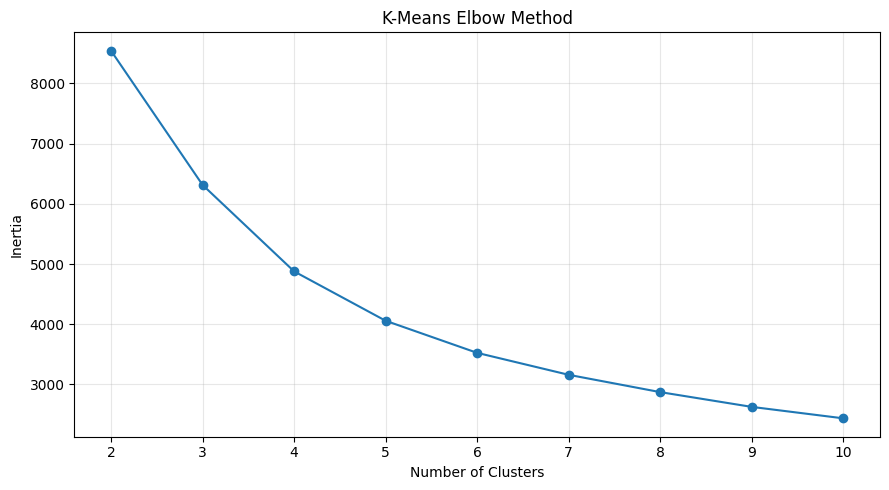

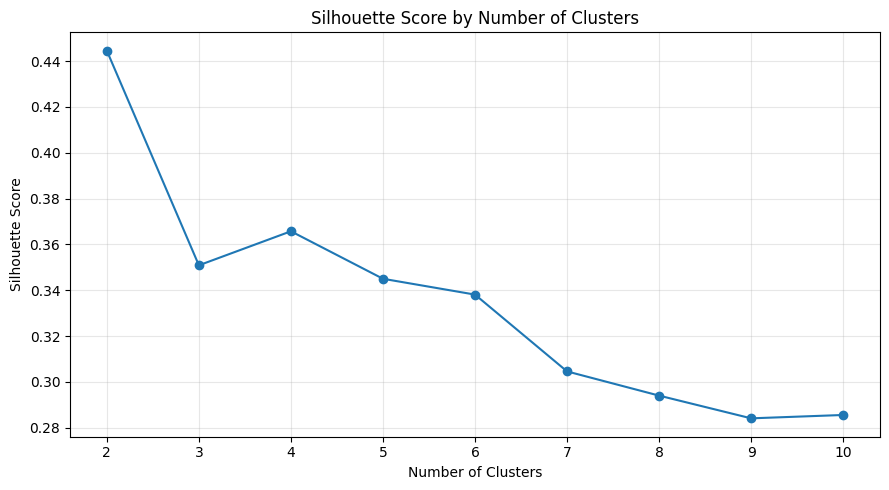


BEST K BY SILHOUETTE SCORE: 2


In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use only scaled RFM features, never customer ID
clustering_features = [
    "Recency_Scaled",
    "Frequency_Scaled",
    "Monetary_Scaled"
]

X_cluster = rfm_scaled_df[
    clustering_features
].to_numpy()

# Evaluate different numbers of clusters
cluster_numbers = range(2, 11)

inertia_scores = []
silhouette_scores = []

for k in cluster_numbers:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    inertia_scores.append(model.inertia_)

    silhouette_scores.append(
        silhouette_score(
            X_cluster,
            labels,
            sample_size=3000,
            random_state=42
        )
    )

# Display results
cluster_results = pd.DataFrame({
    "Clusters": list(cluster_numbers),
    "Inertia": inertia_scores,
    "Silhouette_Score": silhouette_scores
})

print("1. CLUSTER EVALUATION RESULTS")
display(cluster_results.round(4))

# Elbow plot
plt.figure(figsize=(9, 5))
plt.plot(
    cluster_results["Clusters"],
    cluster_results["Inertia"],
    marker="o"
)
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Silhouette plot
plt.figure(figsize=(9, 5))
plt.plot(
    cluster_results["Clusters"],
    cluster_results["Silhouette_Score"],
    marker="o"
)
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_k = int(
    cluster_results.loc[
        cluster_results["Silhouette_Score"].idxmax(),
        "Clusters"
    ]
)

print("\nBEST K BY SILHOUETTE SCORE:", best_k)


In [35]:

import pandas as pd
import numpy as np
import os

from sklearn.cluster import KMeans
from google.colab import files

# Compare two candidate solutions
cluster_profiles = []
cluster_models = {}

for k in [2, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)
    cluster_models[k] = model

    # Use original RFM values for interpretation
    temp = customer_features_df[
        ["Customer_ID", "Recency_Days",
         "Frequency", "Monetary"]
    ].copy()

    temp["Cluster"] = labels

    profile = (
        temp.groupby("Cluster")
        .agg(
            Customers=("Customer_ID", "count"),
            Median_Recency_Days=("Recency_Days", "median"),
            Median_Frequency=("Frequency", "median"),
            Median_Monetary_GBP=("Monetary", "median"),
            Total_Monetary_GBP=("Monetary", "sum")
        )
        .reset_index()
    )

    profile.insert(0, "K", k)

    profile["Customer_Percentage"] = (
        profile["Customers"] / len(temp) * 100
    )

    cluster_profiles.append(profile)

comparison_df = pd.concat(
    cluster_profiles,
    ignore_index=True
)

print("CLUSTER PROFILE COMPARISON")
display(comparison_df.round(2))

# Save comparison CSV
filename = "step25_kmeans_cluster_profile_comparison.csv"
filepath = os.path.join(output_folder, filename)

comparison_df.to_csv(filepath, index=False)

print("\nFILE SAVED:", filename)

files.download(filepath)


CLUSTER PROFILE COMPARISON


,K,Cluster,Customers,Median_Recency_Days,Median_Frequency,Median_Monetary_GBP,Total_Monetary_GBP,Customer_Percentage
0,2,0,2336,24.02,8.0,2823.17,15016369.27,39.92
1,2,1,3516,289.47,2.0,411.33,2108797.72,60.08
2,4,0,1447,185.91,4.0,1450.70,2779614.42,24.73
3,4,1,1258,24.13,3.0,720.36,1062828.19,21.50
4,4,2,1194,17.02,13.0,4898.69,12663193.14,20.40
5,4,3,1953,402.05,1.0,277.40,619531.25,33.37



FILE SAVED: step25_kmeans_cluster_profile_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

import pandas as pd
import os
import joblib
import zipfile

from google.colab import files

# Reuse the K=4 model from Step 25
final_kmeans = cluster_models[4]

# Predict segment numbers
segment_labels = final_kmeans.predict(X_cluster)

# Create final segmented customer dataset
segmented_customers_df = customer_features_df.copy()

segmented_customers_df["Cluster"] = segment_labels

# Descriptive names based on Step 25 profiles
segment_names = {
    0: "Previously Active Customers",
    1: "Recent Developing Customers",
    2: "High-Value Active Customers",
    3: "Infrequent / Inactive Customers"
}

segmented_customers_df["Customer_Segment"] = (
    segmented_customers_df["Cluster"].map(segment_names)
)

print("1. FINAL CUSTOMER SEGMENTS")

segment_summary = (
    segmented_customers_df.groupby(
        ["Cluster", "Customer_Segment"]
    )
    .agg(
        Customers=("Customer_ID", "count"),
        Median_Recency_Days=("Recency_Days", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary_GBP=("Monetary", "median"),
        Total_Monetary_GBP=("Monetary", "sum")
    )
    .reset_index()
)

segment_summary["Customer_Share_Pct"] = (
    segment_summary["Customers"] /
    len(segmented_customers_df) * 100
)

segment_summary["Spending_Share_Pct"] = (
    segment_summary["Total_Monetary_GBP"] /
    segment_summary["Total_Monetary_GBP"].sum() * 100
)

display(segment_summary.round(2))

print("\n2. SAMPLE LABELED CUSTOMERS")

display(
    segmented_customers_df[
        [
            "Customer_ID", "Recency_Days",
            "Frequency", "Monetary",
            "Cluster", "Customer_Segment"
        ]
    ].head(10)
)

# Save outputs
os.makedirs(output_folder, exist_ok=True)

customer_csv = os.path.join(
    output_folder,
    "step26_segmented_customers.csv"
)

summary_csv = os.path.join(
    output_folder,
    "step26_customer_segment_summary.csv"
)

model_path = os.path.join(
    output_folder,
    "step26_kmeans_4_clusters.joblib"
)

segmented_customers_df.to_csv(customer_csv, index=False)
segment_summary.to_csv(summary_csv, index=False)
joblib.dump(final_kmeans, model_path)

# Package into one download
zip_path = os.path.join(
    output_folder,
    "step26_customer_segmentation_files.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    for path in [customer_csv, summary_csv, model_path]:
        z.write(path, arcname=os.path.basename(path))

print("\n3. FILES SAVED SUCCESSFULLY")
print(os.path.basename(customer_csv))
print(os.path.basename(summary_csv))
print(os.path.basename(model_path))

files.download(zip_path)


1. FINAL CUSTOMER SEGMENTS


,Cluster,Customer_Segment,Customers,Median_Recency_Days,Median_Frequency,Median_Monetary_GBP,Total_Monetary_GBP,Customer_Share_Pct,Spending_Share_Pct
0,0,Previously Active Customers,1447,185.91,4.0,1450.70,2779614.42,24.73,16.23
1,1,Recent Developing Customers,1258,24.13,3.0,720.36,1062828.19,21.50,6.21
2,2,High-Value Active Customers,1194,17.02,13.0,4898.69,12663193.14,20.40,73.94
3,3,Infrequent / Inactive Customers,1953,402.05,1.0,277.40,619531.25,33.37,3.62



2. SAMPLE LABELED CUSTOMERS


,Customer_ID,Recency_Days,Frequency,Monetary,Cluster,Customer_Segment
0,12346,326.117361,12,77556.46,2,High-Value Active Customers
1,12347,2.873611,8,4921.53,2,High-Value Active Customers
2,12348,75.984028,5,1658.40,0,Previously Active Customers
3,12349,19.124306,3,3678.69,1,Recent Developing Customers
4,12350,310.867361,1,294.40,3,Infrequent / Inactive Customers
5,12351,375.893750,1,300.93,3,Infrequent / Inactive Customers
6,12352,36.925694,9,1729.54,2,High-Value Active Customers
7,12353,204.793750,2,406.76,3,Infrequent / Inactive Customers
8,12354,232.985417,1,1079.40,3,Infrequent / Inactive Customers
9,12355,214.959028,2,947.61,0,Previously Active Customers



3. FILES SAVED SUCCESSFULLY
step26_segmented_customers.csv
step26_customer_segment_summary.csv
step26_kmeans_4_clusters.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:

import pandas as pd
import os
from google.colab import files

# Start from transaction-level data, not full-history RFM
transactions = customer_transactions_df.copy()

transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"]
)

# Define observation and future periods
cutoff = pd.Timestamp("2011-07-01")
future_end = cutoff + pd.Timedelta(days=90)

# History: strictly before July 1
history_df = transactions.loc[
    transactions["InvoiceDate"] < cutoff
].copy()

# Future: July 1 through the next 90 days
future_df = transactions.loc[
    (transactions["InvoiceDate"] >= cutoff) &
    (transactions["InvoiceDate"] < future_end)
].copy()

# Customers eligible for prediction:
# known customers with at least one purchase before cutoff
historical_customers = (
    history_df["Customer_ID"]
    .drop_duplicates()
)

# Customers who purchased during the future period
returning_customers = set(
    future_df["Customer_ID"]
)

# Construct customer-level outcomes
churn_snapshot = pd.DataFrame({
    "Customer_ID": historical_customers
})

churn_snapshot["Churn_90D"] = (
    ~churn_snapshot["Customer_ID"].isin(
        returning_customers
    )
).astype(int)

print("1. HISTORICAL SNAPSHOT")

print("Prediction date:", cutoff.date())
print("Future window ends:", future_end.date())

print("Historical transaction rows:", len(history_df))
print("Future transaction rows:", len(future_df))

print("\n2. CUSTOMER OUTCOME DISTRIBUTION")

summary = churn_snapshot["Churn_90D"].value_counts()

display(
    pd.DataFrame({
        "Customers": summary,
        "Percentage": (
            churn_snapshot["Churn_90D"]
            .value_counts(normalize=True) * 100
        ).round(2)
    })
)

print("\n3. FIRST FIVE CUSTOMER LABELS")

display(churn_snapshot.head())

print("\n4. SNAPSHOT VALIDATION")

print("Customers:", len(churn_snapshot))
print(
    "Duplicate customer IDs:",
    churn_snapshot["Customer_ID"].duplicated().sum()
)

# Save the historical outcome labels
filename = "step27_customer_churn_90day_labels.csv"
filepath = os.path.join(output_folder, filename)

churn_snapshot.to_csv(filepath, index=False)

print("\n5. FILE SAVED:", filename)

files.download(filepath)


1. HISTORICAL SNAPSHOT
Prediction date: 2011-07-01
Future window ends: 2011-09-29
Historical transaction rows: 563816
Future transaction rows: 89815

2. CUSTOMER OUTCOME DISTRIBUTION


,Customers,Percentage
Churn_90D,,
1,3305,65.89
0,1711,34.11



3. FIRST FIVE CUSTOMER LABELS


,Customer_ID,Churn_90D
0,13085,0
12,13078,0
31,15362,1
54,18102,0
71,12682,0



4. SNAPSHOT VALIDATION
Customers: 5016
Duplicate customer IDs: 0

5. FILE SAVED: step27_customer_churn_90day_labels.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:

import pandas as pd
import os
from google.colab import files

# Use only historical transactions from Step 27
hist = history_df.copy()

# Customer-level historical features
historical_features = (
    hist.groupby("Customer_ID")
    .agg(
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max"),
        Frequency=("Invoice_ID", "nunique"),
        Monetary=("Line_Value", "sum"),
        Total_Units=("Quantity", "sum"),
        Unique_Products=("StockCode", "nunique")
    )
    .reset_index()
)

# Recency: days since latest purchase
historical_features["Recency_Days"] = (
    cutoff - historical_features["Last_Purchase"]
).dt.total_seconds() / 86400

# Time since first observed purchase
historical_features["Customer_Tenure_Days"] = (
    cutoff - historical_features["First_Purchase"]
).dt.total_seconds() / 86400

# Average value per invoice
historical_features["Avg_Invoice_Value"] = (
    historical_features["Monetary"] /
    historical_features["Frequency"]
)

# Active months
hist["Purchase_Month"] = (
    hist["InvoiceDate"].dt.to_period("M")
)

active_months = (
    hist.groupby("Customer_ID")["Purchase_Month"]
    .nunique()
)

historical_features["Active_Months"] = (
    historical_features["Customer_ID"].map(
        active_months
    )
)

# Add future labels WITHOUT using future data as features
churn_model_df = historical_features.merge(
    churn_snapshot,
    on="Customer_ID",
    how="inner",
    validate="one_to_one"
)

print("1. MODEL DATASET SHAPE")
print(churn_model_df.shape)

print("\n2. FIRST FIVE RECORDS")
display(churn_model_df.head())

print("\n3. MISSING VALUES")
display(
    churn_model_df.isna().sum()
    .to_frame("Missing Values")
)

print("\n4. LABEL DISTRIBUTION")
display(
    churn_model_df["Churn_90D"]
    .value_counts()
    .to_frame("Customers")
)

# Verify customer coverage
assert len(churn_model_df) == len(churn_snapshot)
assert churn_model_df["Customer_ID"].is_unique
assert (churn_model_df["Last_Purchase"] < cutoff).all()

print("\nHistorical feature validation passed!")

# Save and download CSV
filename = "step28_historical_customer_churn_features.csv"
filepath = os.path.join(output_folder, filename)

churn_model_df.to_csv(filepath, index=False)

print("\nFILE SAVED:", filename)
files.download(filepath)


1. MODEL DATASET SHAPE
(5016, 12)

2. FIRST FIVE RECORDS


,Customer_ID,First_Purchase,Last_Purchase,Frequency,Monetary,Total_Units,Unique_Products,Recency_Days,Customer_Tenure_Days,Avg_Invoice_Value,Active_Months,Churn_90D
0,12346,2009-12-14 08:34:00,2011-01-18 10:01:00,12,77556.46,74285,27,163.582639,563.643056,6463.038333,5,1
1,12347,2010-10-31 14:20:00,2011-06-09 13:01:00,5,2817.48,1822,101,21.457639,242.402778,563.496000,5,0
2,12348,2010-09-27 14:59:00,2011-04-05 10:47:00,4,1388.40,2488,24,86.550694,276.375694,347.100000,4,0
3,12349,2010-04-29 13:20:00,2010-10-28 08:23:00,2,2221.14,991,89,245.650694,427.444444,1110.570000,2,1
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.40,196,16,148.332639,148.332639,294.400000,1,1



3. MISSING VALUES


,Missing Values
Customer_ID,0
First_Purchase,0
Last_Purchase,0
Frequency,0
Monetary,0
Total_Units,0
Unique_Products,0
Recency_Days,0
Customer_Tenure_Days,0
Avg_Invoice_Value,0



4. LABEL DISTRIBUTION


,Customers
Churn_90D,
1,3305
0,1711



Historical feature validation passed!

FILE SAVED: step28_historical_customer_churn_features.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

import pandas as pd
import os
import zipfile

from sklearn.model_selection import train_test_split
from google.colab import files

# Features available at the prediction cutoff
feature_columns = [
    "Frequency",
    "Monetary",
    "Total_Units",
    "Unique_Products",
    "Recency_Days",
    "Customer_Tenure_Days",
    "Avg_Invoice_Value",
    "Active_Months"
]

X = churn_model_df[feature_columns].copy()
y = churn_model_df["Churn_90D"].copy()

# Keep customer IDs only for audit/export
customer_ids = churn_model_df["Customer_ID"].copy()

# Split customer row indices
all_indices = churn_model_df.index.to_numpy()

train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=42,
    stratify=y
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=y.loc[temp_idx]
)

# Construct each dataset
train_data = churn_model_df.loc[train_idx].copy()
val_data = churn_model_df.loc[val_idx].copy()
test_data = churn_model_df.loc[test_idx].copy()

X_train = train_data[feature_columns]
y_train = train_data["Churn_90D"]

X_val = val_data[feature_columns]
y_val = val_data["Churn_90D"]

X_test = test_data[feature_columns]
y_test = test_data["Churn_90D"]

# Show class distribution
print("1. DATASET SPLITS")

summary = pd.DataFrame([
    {
        "Dataset": name,
        "Customers": len(data),
        "Churn Cases": data["Churn_90D"].sum(),
        "Churn Rate (%)": round(
            data["Churn_90D"].mean() * 100, 2
        )
    }
    for name, data in [
        ("Training", train_data),
        ("Validation", val_data),
        ("Testing", test_data)
    ]
])

display(summary)

print("\n2. MODEL INPUT FEATURES")
print(feature_columns)

print("\n3. SPLIT VALIDATION")

train_customers = set(train_data["Customer_ID"])
val_customers = set(val_data["Customer_ID"])
test_customers = set(test_data["Customer_ID"])

print(
    "Train vs Validation overlap:",
    len(train_customers & val_customers)
)

print(
    "Train vs Test overlap:",
    len(train_customers & test_customers)
)

print(
    "Validation vs Test overlap:",
    len(val_customers & test_customers)
)

assert len(train_customers & val_customers) == 0
assert len(train_customers & test_customers) == 0
assert len(val_customers & test_customers) == 0

# Save split files
os.makedirs(output_folder, exist_ok=True)

split_files = {
    "step29_churn_training.csv": train_data,
    "step29_churn_validation.csv": val_data,
    "step29_churn_testing.csv": test_data
}

zip_path = os.path.join(
    output_folder,
    "step29_churn_dataset_splits.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    for filename, data in split_files.items():
        filepath = os.path.join(output_folder, filename)
        data.to_csv(filepath, index=False)
        z.write(filepath, arcname=filename)

print("\n4. FILES SAVED SUCCESSFULLY")
print(list(split_files.keys()))

files.download(zip_path)


1. DATASET SPLITS


,Dataset,Customers,Churn Cases,Churn Rate (%)
0,Training,3511,2313,65.88
1,Validation,752,496,65.96
2,Testing,753,496,65.87



2. MODEL INPUT FEATURES
['Frequency', 'Monetary', 'Total_Units', 'Unique_Products', 'Recency_Days', 'Customer_Tenure_Days', 'Avg_Invoice_Value', 'Active_Months']

3. SPLIT VALIDATION
Train vs Validation overlap: 0
Train vs Test overlap: 0
Validation vs Test overlap: 0

4. FILES SAVED SUCCESSFULLY
['step29_churn_training.csv', 'step29_churn_validation.csv', 'step29_churn_testing.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:

%pip install -q catboost

import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Create the CatBoost classifier
churn_model = CatBoostClassifier(
    iterations=1000,
    depth=5,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    thread_count=2
)

# Train on training data only
churn_model.fit(
    X_train,
    y_train,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

# Predict validation probabilities
val_probabilities = churn_model.predict_proba(
    X_val
)[:, 1]

# Convert probabilities into predictions
val_predictions = (
    val_probabilities >= 0.50
).astype(int)

# Majority-class baseline
baseline_predictions = np.ones(
    len(y_val),
    dtype=int
)

# Compare performance
results = pd.DataFrame([
    {
        "Model": "Majority Class Baseline",
        "Accuracy": accuracy_score(
            y_val, baseline_predictions
        ),
        "Precision": precision_score(
            y_val, baseline_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, baseline_predictions
        ),
        "F1": f1_score(
            y_val, baseline_predictions
        )
    },
    {
        "Model": "CatBoost",
        "Accuracy": accuracy_score(
            y_val, val_predictions
        ),
        "Precision": precision_score(
            y_val, val_predictions
        ),
        "Recall": recall_score(
            y_val, val_predictions
        ),
        "F1": f1_score(
            y_val, val_predictions
        )
    }
])

print("\n1. MODEL COMPARISON")
display(results.round(4))

print("\n2. CATBOOST VALIDATION METRICS")

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_val, val_probabilities
        ), 4
    )
)

print(
    "PR-AUC (Average Precision):",
    round(
        average_precision_score(
            y_val, val_probabilities
        ), 4
    )
)

print("\n3. CONFUSION MATRIX")

cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1]
)

display(pd.DataFrame(
    cm,
    index=["Actual Return", "Actual Non-Return"],
    columns=[
        "Predicted Return",
        "Predicted Non-Return"
    ]
))

print("\n4. TRAINING INFORMATION")

print(
    "Best iteration:",
    churn_model.get_best_iteration()
)

print(
    "Features used:",
    X_train.columns.tolist()
)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.7 MB/s eta 0:00:00
0:	test: 0.8357052	best: 0.8357052 (0)	total: 51.1ms	remaining: 51s
100:	test: 0.8548387	best: 0.8548938 (91)	total: 393ms	remaining: 3.5s
200:	test: 0.8544607	best: 0.8557444 (115)	total: 706ms	remaining: 2.81s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8557443926
bestIteration = 115

Shrink model to first 116 iterations.

1. MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,Majority Class Baseline,0.6596,0.6596,1.0000,0.7949
1,CatBoost,0.8045,0.8099,0.9194,0.8612



2. CATBOOST VALIDATION METRICS
ROC-AUC: 0.8557
PR-AUC (Average Precision): 0.9116

3. CONFUSION MATRIX


,Predicted Return,Predicted Non-Return
Actual Return,149,107
Actual Non-Return,40,456



4. TRAINING INFORMATION
Best iteration: 115
Features used: ['Frequency', 'Monetary', 'Total_Units', 'Unique_Products', 'Recency_Days', 'Customer_Tenure_Days', 'Avg_Invoice_Value', 'Active_Months']


1. CATBOOST FEATURE IMPORTANCE


,Feature,Importance
0,Recency_Days,34.408
1,Active_Months,14.972
2,Frequency,11.319
3,Total_Units,10.993
4,Customer_Tenure_Days,9.795
5,Monetary,9.396
6,Unique_Products,4.780
7,Avg_Invoice_Value,4.337


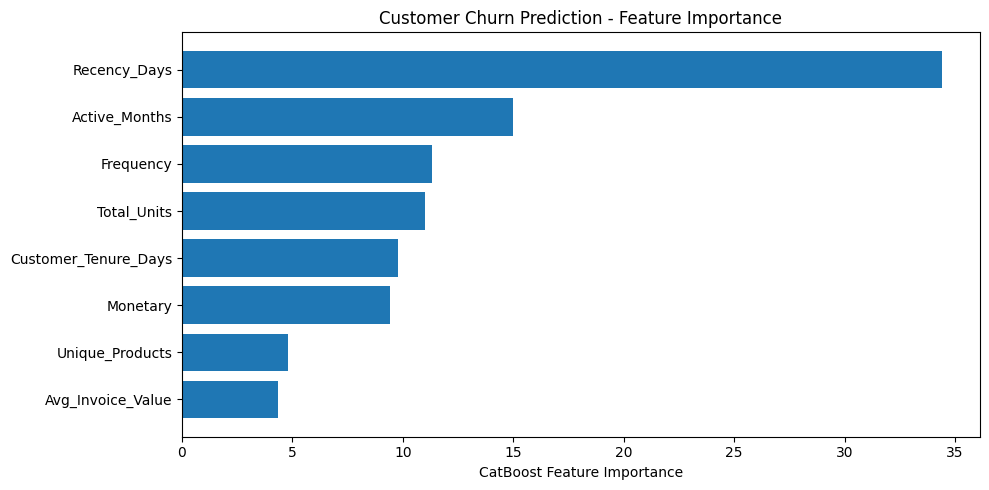


2. SAMPLE VALIDATION PREDICTIONS


,Customer_ID,Churn_90D,Predicted_Probability,Predicted_Churn,Correct_Prediction
702,13215,1,0.911745,1,True
1627,14324,1,0.837302,1,True
1089,13686,1,0.641386,1,True
4895,18146,0,0.735610,1,False
2110,14885,0,0.822838,1,False
1556,14243,0,0.136799,0,True
4911,18165,1,0.574634,1,True
2534,15378,1,0.909397,1,True
3966,17060,1,0.804598,1,True
4605,17801,1,0.810600,1,True



3. FILES SAVED SUCCESSFULLY
step31_catboost_feature_importance.csv
step31_churn_validation_predictions.csv
step31_catboost_churn_baseline.cbm


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:

import pandas as pd
import matplotlib.pyplot as plt
import os
import zipfile
from google.colab import files

# Extract feature importance from trained CatBoost
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": churn_model.get_feature_importance()
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("1. CATBOOST FEATURE IMPORTANCE")
display(importance_df.round(3))

# Plot
plt.figure(figsize=(10, 5))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.xlabel("CatBoost Feature Importance")
plt.title("Customer Churn Prediction - Feature Importance")
plt.tight_layout()
plt.show()

# Save validation predictions for analysis
validation_predictions_df = val_data[
    ["Customer_ID", "Churn_90D"]
].copy()

validation_predictions_df["Predicted_Probability"] = (
    val_probabilities
)

validation_predictions_df["Predicted_Churn"] = (
    val_predictions
)

validation_predictions_df["Correct_Prediction"] = (
    validation_predictions_df["Churn_90D"] ==
    validation_predictions_df["Predicted_Churn"]
)

print("\n2. SAMPLE VALIDATION PREDICTIONS")
display(validation_predictions_df.head(10))

# Save model and outputs
os.makedirs(output_folder, exist_ok=True)

importance_path = os.path.join(
    output_folder,
    "step31_catboost_feature_importance.csv"
)

predictions_path = os.path.join(
    output_folder,
    "step31_churn_validation_predictions.csv"
)

model_path = os.path.join(
    output_folder,
    "step31_catboost_churn_baseline.cbm"
)

importance_df.to_csv(importance_path, index=False)
validation_predictions_df.to_csv(
    predictions_path,
    index=False
)

churn_model.save_model(model_path)

# Download all files in one ZIP
zip_path = os.path.join(
    output_folder,
    "step31_churn_model_analysis_files.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    for path in [
        importance_path,
        predictions_path,
        model_path
    ]:
        z.write(path, arcname=os.path.basename(path))

print("\n3. FILES SAVED SUCCESSFULLY")
print(os.path.basename(importance_path))
print(os.path.basename(predictions_path))
print(os.path.basename(model_path))

files.download(zip_path)


1. THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1,False_Alarms,Missed_Non_Returns,Predicted_Non_Returns
0,0.20,0.7261,0.7095,0.9899,0.8266,201,5,692
1,0.25,0.7394,0.7239,0.9778,0.8319,185,11,670
2,0.30,0.7620,0.7465,0.9677,0.8428,163,16,643
3,0.35,0.7753,0.7608,0.9617,0.8495,150,19,627
4,0.40,0.7872,0.7781,0.9476,0.8545,134,26,604
5,0.45,0.7979,0.7945,0.9355,0.8593,120,32,584
6,0.50,0.8045,0.8099,0.9194,0.8612,107,40,563
7,0.55,0.8045,0.8237,0.8952,0.8580,95,52,539
8,0.60,0.7939,0.8417,0.8468,0.8442,79,76,499
9,0.65,0.7766,0.8596,0.7903,0.8235,64,104,456



2. BEST THRESHOLD BY F1
Threshold: 0.5
F1: 0.8612
Precision: 0.8099
Recall: 0.9194
False alarms: 107
Missed non-returns: 40


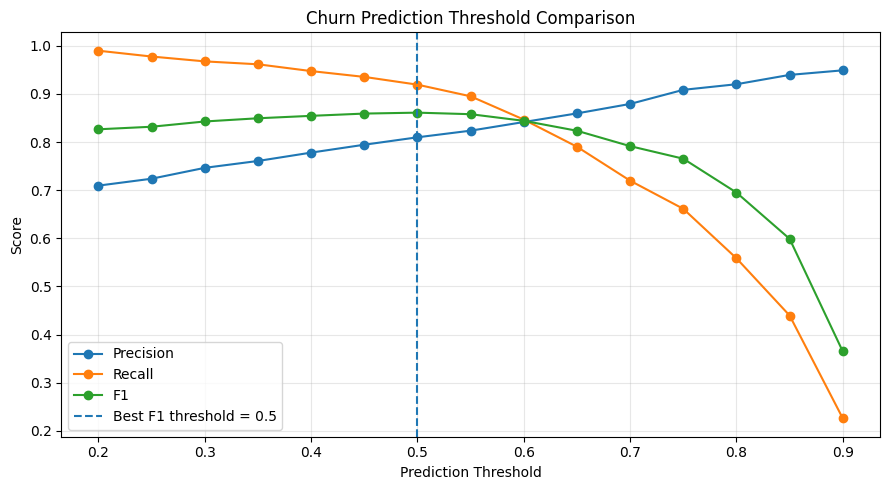


3. FILE SAVED: step32_churn_probability_threshold_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from google.colab import files

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Evaluate thresholds on VALIDATION data only
thresholds = np.round(np.arange(0.20, 0.91, 0.05), 2)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False_Alarms": fp,
        "Missed_Non_Returns": fn,
        "Predicted_Non_Returns": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

print("1. THRESHOLD COMPARISON")
display(threshold_df.round(4))

# Select the threshold with highest validation F1
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("\n2. BEST THRESHOLD BY F1")
print("Threshold:", best_threshold)
print("F1:", round(best_row["F1"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("False alarms:", int(best_row["False_Alarms"]))
print("Missed non-returns:", int(best_row["Missed_Non_Returns"]))

# Compare metrics visually
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best F1 threshold = {best_threshold}"
)

plt.xlabel("Prediction Threshold")
plt.ylabel("Score")
plt.title("Churn Prediction Threshold Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save results
filename = "step32_churn_probability_threshold_comparison.csv"

filepath = os.path.join(output_folder, filename)

threshold_df.to_csv(filepath, index=False)

print("\n3. FILE SAVED:", filename)
files.download(filepath)


In [43]:

import numpy as np
import pandas as pd
import os
import zipfile

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
from google.colab import files

# Use the selected validation threshold
selected_threshold = best_threshold

# Predict on the untouched test dataset
test_probabilities = churn_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Majority-class baseline
baseline_test = np.ones(len(y_test), dtype=int)

def calculate_metrics(actual, predictions, probabilities=None):
    result = {
        "Accuracy": accuracy_score(actual, predictions),
        "Precision": precision_score(actual, predictions, zero_division=0),
        "Recall": recall_score(actual, predictions, zero_division=0),
        "F1": f1_score(actual, predictions, zero_division=0)
    }

    if probabilities is not None:
        result["ROC_AUC"] = roc_auc_score(actual, probabilities)
        result["PR_AUC"] = average_precision_score(
            actual, probabilities
        )
    else:
        result["ROC_AUC"] = np.nan
        result["PR_AUC"] = np.nan

    return result

# Compare models
test_results_df = pd.DataFrame([
    {
        "Model": "Majority Class Baseline",
        **calculate_metrics(y_test, baseline_test)
    },
    {
        "Model": "CatBoost",
        **calculate_metrics(
            y_test,
            test_predictions,
            test_probabilities
        )
    }
])

print("1. FINAL TEST RESULTS")
display(test_results_df.round(4))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual Return",
        "Actual Non-Return"
    ],
    columns=[
        "Predicted Return",
        "Predicted Non-Return"
    ]
)

print("\n2. TEST CONFUSION MATRIX")
display(cm_df)

# Validation vs test comparison
validation_metrics = calculate_metrics(
    y_val,
    val_predictions,
    val_probabilities
)

test_metrics = calculate_metrics(
    y_test,
    test_predictions,
    test_probabilities
)

comparison_df = pd.DataFrame({
    "Metric": list(validation_metrics.keys()),
    "Validation": list(validation_metrics.values()),
    "Test": list(test_metrics.values())
})

print("\n3. VALIDATION VS TEST PERFORMANCE")
display(comparison_df.round(4))

# Save customer-level test predictions
test_predictions_df = test_data[
    ["Customer_ID", "Churn_90D"]
].copy()

test_predictions_df["Predicted_Probability"] = (
    test_probabilities
)

test_predictions_df["Predicted_Churn"] = (
    test_predictions
)

test_predictions_df["Correct_Prediction"] = (
    test_predictions_df["Churn_90D"] ==
    test_predictions_df["Predicted_Churn"]
)

# Save CSV files
os.makedirs(output_folder, exist_ok=True)

files_to_save = {
    "step33_churn_final_test_metrics.csv": test_results_df,
    "step33_churn_test_confusion_matrix.csv": cm_df,
    "step33_churn_validation_vs_test.csv": comparison_df,
    "step33_churn_test_predictions.csv": test_predictions_df
}

zip_path = os.path.join(
    output_folder,
    "step33_churn_test_evaluation_files.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    for filename, data in files_to_save.items():
        filepath = os.path.join(output_folder, filename)
        data.to_csv(filepath, index=False)
        z.write(filepath, arcname=filename)

print("\n4. FILES SAVED SUCCESSFULLY")
for filename in files_to_save:
    print(filename)

files.download(zip_path)


1. FINAL TEST RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Majority Class Baseline,0.6587,0.6587,1.0000,0.7942,NaN,NaN
1,CatBoost,0.7583,0.7679,0.9073,0.8318,0.7995,0.8727



2. TEST CONFUSION MATRIX


,Predicted Return,Predicted Non-Return
Actual Return,121,136
Actual Non-Return,46,450



3. VALIDATION VS TEST PERFORMANCE


,Metric,Validation,Test
0,Accuracy,0.8045,0.7583
1,Precision,0.8099,0.7679
2,Recall,0.9194,0.9073
3,F1,0.8612,0.8318
4,ROC_AUC,0.8557,0.7995
5,PR_AUC,0.9116,0.8727



4. FILES SAVED SUCCESSFULLY
step33_churn_final_test_metrics.csv
step33_churn_test_confusion_matrix.csv
step33_churn_validation_vs_test.csv
step33_churn_test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:

import pandas as pd
import os
from google.colab import files

# Use the original customer transactions
transactions = customer_transactions_df.copy()

transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"]
)

# Each future window is 90 days
prediction_dates = [
    "2010-10-01",
    "2011-01-01",
    "2011-04-01",
    "2011-07-01"
]

snapshot_rows = []
snapshot_summary = []

# Keep every snapshot separate
for date_string in prediction_dates:

    snapshot_cutoff = pd.Timestamp(date_string)
    snapshot_end = (
        snapshot_cutoff + pd.Timedelta(days=90)
    )

    # All purchases BEFORE the prediction date
    historical = transactions.loc[
        transactions["InvoiceDate"] < snapshot_cutoff
    ]

    # Purchases AFTER the prediction date
    future = transactions.loc[
        (transactions["InvoiceDate"] >= snapshot_cutoff) &
        (transactions["InvoiceDate"] < snapshot_end)
    ]

    customers = historical[
        "Customer_ID"
    ].drop_duplicates()

    returning = set(
        future["Customer_ID"]
    )

    snapshot = pd.DataFrame({
        "Customer_ID": customers
    })

    snapshot["Snapshot_Date"] = snapshot_cutoff

    snapshot["Churn_90D"] = (
        ~snapshot["Customer_ID"].isin(returning)
    ).astype(int)

    snapshot_rows.append(snapshot)

    snapshot_summary.append({
        "Snapshot_Date": snapshot_cutoff.date(),
        "Customers": len(snapshot),
        "Non_Returning": int(snapshot["Churn_90D"].sum()),
        "Returning": int((snapshot["Churn_90D"] == 0).sum()),
        "Non_Return_Rate_Pct": round(
            snapshot["Churn_90D"].mean() * 100, 2
        ),
        "Future_Window_End": snapshot_end.date()
    })

# Combine snapshots
chronological_labels_df = pd.concat(
    snapshot_rows,
    ignore_index=True
)

chronological_summary_df = pd.DataFrame(
    snapshot_summary
)

print("1. CHRONOLOGICAL SNAPSHOT SUMMARY")
display(chronological_summary_df)

print("\n2. TOTAL SNAPSHOT ROWS")
print(len(chronological_labels_df))

print("\n3. SNAPSHOT VALIDATION")

duplicate_pairs = chronological_labels_df.duplicated(
    ["Customer_ID", "Snapshot_Date"]
).sum()

print("Duplicate customer-date pairs:", duplicate_pairs)

assert duplicate_pairs == 0

# Confirm each 90-day future window is observable
dataset_end = transactions["InvoiceDate"].max()

for date_string in prediction_dates:
    end = pd.Timestamp(date_string) + pd.Timedelta(days=90)
    assert end <= dataset_end, (
        f"Insufficient future data for {date_string}"
    )

print("All future windows are within the dataset.")

# Save the datasets
os.makedirs(output_folder, exist_ok=True)

labels_filename = (
    "step34_chronological_90day_churn_labels.csv"
)

summary_filename = (
    "step34_chronological_snapshot_summary.csv"
)

labels_path = os.path.join(
    output_folder,
    labels_filename
)

summary_path = os.path.join(
    output_folder,
    summary_filename
)

chronological_labels_df.to_csv(
    labels_path,
    index=False
)

chronological_summary_df.to_csv(
    summary_path,
    index=False
)

# Download as one ZIP
import zipfile

zip_path = os.path.join(
    output_folder,
    "step34_chronological_churn_snapshots.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    z.write(labels_path, arcname=labels_filename)
    z.write(summary_path, arcname=summary_filename)

print("\n4. FILES SAVED SUCCESSFULLY")
print(labels_filename)
print(summary_filename)

files.download(zip_path)


1. CHRONOLOGICAL SNAPSHOT SUMMARY


,Snapshot_Date,Customers,Non_Returning,Returning,Non_Return_Rate_Pct,Future_Window_End
0,2010-10-01,3538,1650,1888,46.64,2010-12-30
1,2011-01-01,4315,2917,1398,67.60,2011-04-01
2,2011-04-01,4691,3039,1652,64.78,2011-06-30
3,2011-07-01,5016,3305,1711,65.89,2011-09-29



2. TOTAL SNAPSHOT ROWS
17560

3. SNAPSHOT VALIDATION
Duplicate customer-date pairs: 0
All future windows are within the dataset.

4. FILES SAVED SUCCESSFULLY
step34_chronological_90day_churn_labels.csv
step34_chronological_snapshot_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

import pandas as pd
import os
from google.colab import files

all_snapshot_features = []

# Process each historical prediction date separately
for date_string in prediction_dates:

    snapshot_cutoff = pd.Timestamp(date_string)

    # Strictly historical transactions
    hist = transactions.loc[
        transactions["InvoiceDate"] < snapshot_cutoff
    ].copy()

    # Aggregate customer behavior
    features = (
        hist.groupby("Customer_ID")
        .agg(
            First_Purchase=("InvoiceDate", "min"),
            Last_Purchase=("InvoiceDate", "max"),
            Frequency=("Invoice_ID", "nunique"),
            Monetary=("Line_Value", "sum"),
            Total_Units=("Quantity", "sum"),
            Unique_Products=("StockCode", "nunique")
        )
        .reset_index()
    )

    # Recency and customer tenure
    features["Recency_Days"] = (
        snapshot_cutoff - features["Last_Purchase"]
    ).dt.total_seconds() / 86400

    features["Customer_Tenure_Days"] = (
        snapshot_cutoff - features["First_Purchase"]
    ).dt.total_seconds() / 86400

    # Average invoice spending
    features["Avg_Invoice_Value"] = (
        features["Monetary"] / features["Frequency"]
    )

    # Number of active purchasing months
    hist["Purchase_Month"] = (
        hist["InvoiceDate"].dt.to_period("M")
    )

    active_months = (
        hist.groupby("Customer_ID")["Purchase_Month"]
        .nunique()
    )

    features["Active_Months"] = (
        features["Customer_ID"].map(active_months)
    )

    # Identify the prediction date
    features["Snapshot_Date"] = snapshot_cutoff

    # Merge the future labels for this snapshot
    snapshot_labels = chronological_labels_df.loc[
        chronological_labels_df["Snapshot_Date"] == snapshot_cutoff,
        ["Customer_ID", "Snapshot_Date", "Churn_90D"]
    ]

    features = features.merge(
        snapshot_labels,
        on=["Customer_ID", "Snapshot_Date"],
        how="inner",
        validate="one_to_one"
    )

    # Verify features do not use future purchases
    assert (features["Last_Purchase"] < snapshot_cutoff).all()

    all_snapshot_features.append(features)

# Combine all snapshots
chronological_features_df = pd.concat(
    all_snapshot_features,
    ignore_index=True
)

print("1. CHRONOLOGICAL FEATURE DATASET SHAPE")
print(chronological_features_df.shape)

print("\n2. SAMPLE RECORDS")
display(chronological_features_df.head())

print("\n3. RECORDS BY SNAPSHOT")

snapshot_counts = (
    chronological_features_df.groupby("Snapshot_Date")
    .agg(
        Customers=("Customer_ID", "count"),
        Non_Returning=("Churn_90D", "sum"),
        Non_Return_Rate=("Churn_90D", "mean")
    )
    .reset_index()
)

snapshot_counts["Non_Return_Rate"] *= 100

display(snapshot_counts.round(2))

print("\n4. MISSING VALUES")
display(
    chronological_features_df.isna().sum()
    .to_frame("Missing Values")
)

print("\n5. DATA VALIDATION")

duplicate_pairs = chronological_features_df.duplicated(
    ["Customer_ID", "Snapshot_Date"]
).sum()

print("Duplicate customer-snapshot pairs:", duplicate_pairs)
print("Total records:", len(chronological_features_df))

assert duplicate_pairs == 0
assert len(chronological_features_df) == 17560
assert chronological_features_df.isna().sum().sum() == 0

print("All validation checks passed!")

# Export the chronological feature dataset
filename = "step35_chronological_customer_churn_features.csv"
filepath = os.path.join(output_folder, filename)

chronological_features_df.to_csv(filepath, index=False)

print("\n6. FILE SAVED SUCCESSFULLY")
print("Filename:", filename)
print(
    "File size:",
    round(os.path.getsize(filepath) / (1024 * 1024), 2),
    "MB"
)

files.download(filepath)


1. CHRONOLOGICAL FEATURE DATASET SHAPE
(17560, 13)

2. SAMPLE RECORDS


,Customer_ID,First_Purchase,Last_Purchase,Frequency,Monetary,Total_Units,Unique_Products,Recency_Days,Customer_Tenure_Days,Avg_Invoice_Value,Active_Months,Snapshot_Date,Churn_90D
0,12346,2009-12-14 08:34:00,2010-06-28 13:53:00,11,372.86,70,26,94.421528,290.643056,33.896364,4,2010-10-01,1
1,12348,2010-09-27 14:59:00,2010-09-27 14:59:00,1,221.16,372,19,3.375694,3.375694,221.160000,1,2010-10-01,0
2,12349,2010-04-29 13:20:00,2010-04-29 13:20:00,1,1068.52,473,46,154.444444,154.444444,1068.520000,1,2010-10-01,0
3,12355,2010-05-21 11:59:00,2010-05-21 11:59:00,1,488.21,303,22,132.500694,132.500694,488.210000,1,2010-10-01,1
4,12358,2009-12-08 07:59:00,2010-06-07 12:28:00,2,1697.93,590,34,115.480556,296.667361,848.965000,2,2010-10-01,0



3. RECORDS BY SNAPSHOT


,Snapshot_Date,Customers,Non_Returning,Non_Return_Rate
0,2010-10-01,3538,1650,46.64
1,2011-01-01,4315,2917,67.60
2,2011-04-01,4691,3039,64.78
3,2011-07-01,5016,3305,65.89



4. MISSING VALUES


,Missing Values
Customer_ID,0
First_Purchase,0
Last_Purchase,0
Frequency,0
Monetary,0
Total_Units,0
Unique_Products,0
Recency_Days,0
Customer_Tenure_Days,0
Avg_Invoice_Value,0



5. DATA VALIDATION
Duplicate customer-snapshot pairs: 0
Total records: 17560
All validation checks passed!

6. FILE SAVED SUCCESSFULLY
Filename: step35_chronological_customer_churn_features.csv
File size: 2.09 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:

import pandas as pd
import os
import zipfile
from google.colab import files

# Work from Step 35
chrono_df = chronological_features_df.copy()

chrono_df["Snapshot_Date"] = pd.to_datetime(
    chrono_df["Snapshot_Date"]
)

# Chronological split
chrono_train_df = chrono_df.loc[
    chrono_df["Snapshot_Date"].isin([
        pd.Timestamp("2010-10-01"),
        pd.Timestamp("2011-01-01")
    ])
].copy()

chrono_val_df = chrono_df.loc[
    chrono_df["Snapshot_Date"] == pd.Timestamp("2011-04-01")
].copy()

chrono_test_df = chrono_df.loc[
    chrono_df["Snapshot_Date"] == pd.Timestamp("2011-07-01")
].copy()

# Same eight features as our original CatBoost model
chrono_feature_columns = [
    "Frequency",
    "Monetary",
    "Total_Units",
    "Unique_Products",
    "Recency_Days",
    "Customer_Tenure_Days",
    "Avg_Invoice_Value",
    "Active_Months"
]

X_chrono_train = chrono_train_df[chrono_feature_columns]
y_chrono_train = chrono_train_df["Churn_90D"]

X_chrono_val = chrono_val_df[chrono_feature_columns]
y_chrono_val = chrono_val_df["Churn_90D"]

X_chrono_test = chrono_test_df[chrono_feature_columns]
y_chrono_test = chrono_test_df["Churn_90D"]

print("1. CHRONOLOGICAL DATASET SUMMARY")

summary = pd.DataFrame([
    {
        "Dataset": name,
        "Records": len(data),
        "Unique_Customers": data["Customer_ID"].nunique(),
        "Churn_Cases": int(data["Churn_90D"].sum()),
        "Churn_Rate_Pct": round(
            data["Churn_90D"].mean() * 100, 2
        ),
        "Earliest_Snapshot": data["Snapshot_Date"].min().date(),
        "Latest_Snapshot": data["Snapshot_Date"].max().date()
    }
    for name, data in [
        ("Training", chrono_train_df),
        ("Validation", chrono_val_df),
        ("Testing", chrono_test_df)
    ]
])

display(summary)

print("\n2. TEMPORAL VALIDATION")

train_last_label_end = (
    chrono_train_df["Snapshot_Date"].max()
    + pd.Timedelta(days=90)
)

val_last_label_end = (
    chrono_val_df["Snapshot_Date"].max()
    + pd.Timedelta(days=90)
)

val_start = chrono_val_df["Snapshot_Date"].min()
test_start = chrono_test_df["Snapshot_Date"].min()

print("Last training label window ends:", train_last_label_end)
print("Validation starts:", val_start)
print("Validation label window ends:", val_last_label_end)
print("Test starts:", test_start)

assert train_last_label_end <= val_start
assert val_last_label_end <= test_start

print("\nNo label-window overlap across splits!")

print("\n3. DATASET VALIDATION")

assert (
    len(chrono_train_df)
    + len(chrono_val_df)
    + len(chrono_test_df)
    == len(chrono_df)
)

assert X_chrono_train.isna().sum().sum() == 0
assert X_chrono_val.isna().sum().sum() == 0
assert X_chrono_test.isna().sum().sum() == 0

print("All checks passed!")

# Save datasets
os.makedirs(output_folder, exist_ok=True)

split_files = {
    "step36_chronological_churn_training.csv": chrono_train_df,
    "step36_chronological_churn_validation.csv": chrono_val_df,
    "step36_chronological_churn_testing.csv": chrono_test_df
}

zip_path = os.path.join(
    output_folder,
    "step36_chronological_churn_splits.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    for filename, data in split_files.items():
        filepath = os.path.join(output_folder, filename)
        data.to_csv(filepath, index=False)
        z.write(filepath, arcname=filename)

print("\n4. FILES SAVED SUCCESSFULLY")
for filename in split_files:
    print(filename)

files.download(zip_path)


1. CHRONOLOGICAL DATASET SUMMARY


,Dataset,Records,Unique_Customers,Churn_Cases,Churn_Rate_Pct,Earliest_Snapshot,Latest_Snapshot
0,Training,7853,4315,4567,58.16,2010-10-01,2011-01-01
1,Validation,4691,4691,3039,64.78,2011-04-01,2011-04-01
2,Testing,5016,5016,3305,65.89,2011-07-01,2011-07-01



2. TEMPORAL VALIDATION
Last training label window ends: 2011-04-01 00:00:00
Validation starts: 2011-04-01 00:00:00
Validation label window ends: 2011-06-30 00:00:00
Test starts: 2011-07-01 00:00:00

No label-window overlap across splits!

3. DATASET VALIDATION
All checks passed!

4. FILES SAVED SUCCESSFULLY
step36_chronological_churn_training.csv
step36_chronological_churn_validation.csv
step36_chronological_churn_testing.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:

import numpy as np
import pandas as pd
import os
import zipfile

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
from google.colab import files

# Train chronological CatBoost model
chrono_model = CatBoostClassifier(
    iterations=1000,
    depth=5,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    thread_count=2
)

chrono_model.fit(
    X_chrono_train,
    y_chrono_train,
    eval_set=(X_chrono_val, y_chrono_val),
    early_stopping_rounds=100,
    use_best_model=True
)

# Predict on April 2011 validation data
chrono_val_prob = chrono_model.predict_proba(
    X_chrono_val
)[:, 1]

chrono_val_pred = (
    chrono_val_prob >= 0.50
).astype(int)

# Majority-class baseline from training distribution
majority_label = int(
    y_chrono_train.mode().iloc[0]
)

baseline_pred = np.full(
    len(y_chrono_val),
    majority_label
)

def evaluate_predictions(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

results_df = pd.DataFrame([
    {
        "Model": "Majority Class Baseline",
        **evaluate_predictions(
            y_chrono_val, baseline_pred
        )
    },
    {
        "Model": "Chronological CatBoost",
        **evaluate_predictions(
            y_chrono_val, chrono_val_pred
        )
    }
])

print("1. CHRONOLOGICAL VALIDATION RESULTS")
display(results_df.round(4))

print("\n2. CHRONOLOGICAL CATBOOST METRICS")

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_chrono_val,
            chrono_val_prob
        ), 4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_chrono_val,
            chrono_val_prob
        ), 4
    )
)

print("\n3. CONFUSION MATRIX")

cm = confusion_matrix(
    y_chrono_val,
    chrono_val_pred,
    labels=[0, 1]
)

display(
    pd.DataFrame(
        cm,
        index=[
            "Actual Return",
            "Actual Non-Return"
        ],
        columns=[
            "Predicted Return",
            "Predicted Non-Return"
        ]
    )
)

print("\n4. TRAINING DETAILS")

print(
    "Best iteration:",
    chrono_model.get_best_iteration()
)

# Save trained model and validation results
os.makedirs(output_folder, exist_ok=True)

model_path = os.path.join(
    output_folder,
    "step37_chronological_catboost_model.cbm"
)

metrics_path = os.path.join(
    output_folder,
    "step37_chronological_validation_metrics.csv"
)

predictions_path = os.path.join(
    output_folder,
    "step37_chronological_validation_predictions.csv"
)

chrono_model.save_model(model_path)
results_df.to_csv(metrics_path, index=False)

predictions_df = chrono_val_df[
    ["Customer_ID", "Snapshot_Date", "Churn_90D"]
].copy()

predictions_df["Predicted_Probability"] = (
    chrono_val_prob
)

predictions_df["Predicted_Churn"] = chrono_val_pred

predictions_df.to_csv(
    predictions_path,
    index=False
)

zip_path = os.path.join(
    output_folder,
    "step37_chronological_catboost_files.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    for path in [
        model_path, metrics_path, predictions_path
    ]:
        z.write(
            path,
            arcname=os.path.basename(path)
        )

print("\n5. FILES SAVED SUCCESSFULLY")
print(os.path.basename(model_path))
print(os.path.basename(metrics_path))
print(os.path.basename(predictions_path))

files.download(zip_path)


0:	test: 0.7465719	best: 0.7465719 (0)	total: 5.92ms	remaining: 5.91s
100:	test: 0.7894824	best: 0.7911863 (41)	total: 530ms	remaining: 4.72s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.7911863291
bestIteration = 41

Shrink model to first 42 iterations.
1. CHRONOLOGICAL VALIDATION RESULTS


,Model,Accuracy,Precision,Recall,F1
0,Majority Class Baseline,0.6478,0.6478,1.0000,0.7863
1,Chronological CatBoost,0.7570,0.7766,0.8773,0.8239



2. CHRONOLOGICAL CATBOOST METRICS
ROC-AUC: 0.7912
PR-AUC: 0.8559

3. CONFUSION MATRIX


,Predicted Return,Predicted Non-Return
Actual Return,885,767
Actual Non-Return,373,2666



4. TRAINING DETAILS
Best iteration: 41

5. FILES SAVED SUCCESSFULLY
step37_chronological_catboost_model.cbm
step37_chronological_validation_metrics.csv
step37_chronological_validation_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:

import numpy as np
import pandas as pd
import os
from google.colab import files

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Validation probabilities from Step 37
thresholds = np.round(
    np.arange(0.20, 0.91, 0.05),
    2
)

chrono_threshold_results = []

for threshold in thresholds:

    predictions = (
        chrono_val_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_chrono_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    chrono_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_chrono_val, predictions
        ),
        "Precision": precision_score(
            y_chrono_val, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_chrono_val, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_chrono_val, predictions,
            zero_division=0
        ),
        "False_Alarms": int(fp),
        "Missed_Non_Returns": int(fn),
        "Predicted_Non_Returns": int(
            predictions.sum()
        )
    })

chrono_threshold_df = pd.DataFrame(
    chrono_threshold_results
)

print("1. CHRONOLOGICAL THRESHOLD COMPARISON")
display(chrono_threshold_df.round(4))

# Select highest F1, breaking ties toward lower threshold
best_index = chrono_threshold_df["F1"].idxmax()

chrono_best_threshold = float(
    chrono_threshold_df.loc[
        best_index, "Threshold"
    ]
)

print("\n2. SELECTED THRESHOLD")
print("Threshold:", chrono_best_threshold)

print(
    "Validation F1:",
    round(
        chrono_threshold_df.loc[best_index, "F1"],
        4
    )
)

print(
    "Validation precision:",
    round(
        chrono_threshold_df.loc[best_index, "Precision"],
        4
    )
)

print(
    "Validation recall:",
    round(
        chrono_threshold_df.loc[best_index, "Recall"],
        4
    )
)

print(
    "False alarms:",
    int(
        chrono_threshold_df.loc[
            best_index, "False_Alarms"
        ]
    )
)

print(
    "Missed non-returns:",
    int(
        chrono_threshold_df.loc[
            best_index, "Missed_Non_Returns"
        ]
    )
)

# Save results and selected threshold
os.makedirs(output_folder, exist_ok=True)

filename = (
    "step38_chronological_churn_threshold_comparison.csv"
)

filepath = os.path.join(
    output_folder,
    filename
)

chrono_threshold_df.to_csv(
    filepath,
    index=False
)

# Save selected threshold for future deployment
threshold_filename = (
    "step38_selected_churn_threshold.csv"
)

threshold_path = os.path.join(
    output_folder,
    threshold_filename
)

pd.DataFrame({
    "Model": ["Chronological CatBoost"],
    "Selected_Threshold": [chrono_best_threshold],
    "Selection_Criterion": ["Validation F1"]
}).to_csv(
    threshold_path,
    index=False
)

# Package files for download
import zipfile

zip_path = os.path.join(
    output_folder,
    "step38_chronological_threshold_files.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    z.write(filepath, arcname=filename)
    z.write(
        threshold_path,
        arcname=threshold_filename
    )

print("\n3. FILES SAVED SUCCESSFULLY")
print(filename)
print(threshold_filename)

files.download(zip_path)


1. CHRONOLOGICAL THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1,False_Alarms,Missed_Non_Returns,Predicted_Non_Returns
0,0.20,0.6559,0.6531,1.0000,0.7902,1614,0,4653
1,0.25,0.7022,0.6872,0.9918,0.8119,1372,25,4386
2,0.30,0.7222,0.7065,0.9773,0.8201,1234,69,4204
3,0.35,0.7410,0.7274,0.9599,0.8276,1093,122,4010
4,0.40,0.7576,0.7491,0.9411,0.8342,958,179,3818
5,0.45,0.7612,0.7628,0.9164,0.8326,866,254,3651
6,0.50,0.7570,0.7766,0.8773,0.8239,767,373,3433
7,0.55,0.7485,0.7935,0.8269,0.8099,654,526,3167
8,0.60,0.7254,0.8148,0.7456,0.7787,515,773,2781
9,0.65,0.6685,0.8467,0.5962,0.6997,328,1227,2140



2. SELECTED THRESHOLD
Threshold: 0.4
Validation F1: 0.8342
Validation precision: 0.7491
Validation recall: 0.9411
False alarms: 958
Missed non-returns: 179

3. FILES SAVED SUCCESSFULLY
step38_chronological_churn_threshold_comparison.csv
step38_selected_churn_threshold.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

import os
import zipfile
import numpy as np
import pandas as pd

from google.colab import files
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)

# --------------------------------------------------
# 1. PREDICT ON JULY 2011 TEST SNAPSHOT
# --------------------------------------------------

chrono_test_prob = chrono_model.predict_proba(
    X_chrono_test
)[:, 1]

chrono_test_pred = (
    chrono_test_prob >= chrono_best_threshold
).astype(int)

# Baseline predicts training's majority class
majority_label = int(y_chrono_train.mode().iloc[0])

baseline_test_pred = np.full(
    len(y_chrono_test),
    majority_label,
    dtype=int
)

# --------------------------------------------------
# 2. PERFORMANCE METRICS
# --------------------------------------------------

def evaluate_chrono(y_true, predictions, probabilities=None):

    metrics = {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        )
    }

    if probabilities is not None:
        metrics["ROC_AUC"] = roc_auc_score(
            y_true, probabilities
        )
        metrics["PR_AUC"] = average_precision_score(
            y_true, probabilities
        )
        metrics["Brier_Score"] = brier_score_loss(
            y_true, probabilities
        )
    else:
        metrics["ROC_AUC"] = np.nan
        metrics["PR_AUC"] = np.nan
        metrics["Brier_Score"] = np.nan

    return metrics


chrono_test_results_df = pd.DataFrame([
    {
        "Model": "Majority Class Baseline",
        **evaluate_chrono(
            y_chrono_test,
            baseline_test_pred
        )
    },
    {
        "Model": "Chronological CatBoost",
        **evaluate_chrono(
            y_chrono_test,
            chrono_test_pred,
            chrono_test_prob
        )
    }
])

print("1. FINAL CHRONOLOGICAL TEST RESULTS")
display(chrono_test_results_df.round(4))

# --------------------------------------------------
# 3. CONFUSION MATRIX
# --------------------------------------------------

cm = confusion_matrix(
    y_chrono_test,
    chrono_test_pred,
    labels=[0, 1]
)

chrono_test_cm_df = pd.DataFrame(
    cm,
    index=["Actual Return", "Actual Non-Return"],
    columns=["Predicted Return", "Predicted Non-Return"]
)

print("\n2. CHRONOLOGICAL TEST CONFUSION MATRIX")
display(chrono_test_cm_df)

# --------------------------------------------------
# 4. VALIDATION VS TEST
# --------------------------------------------------

chrono_val_pred_selected = (
    chrono_val_prob >= chrono_best_threshold
).astype(int)

validation_metrics = evaluate_chrono(
    y_chrono_val,
    chrono_val_pred_selected,
    chrono_val_prob
)

test_metrics = evaluate_chrono(
    y_chrono_test,
    chrono_test_pred,
    chrono_test_prob
)

chrono_val_test_df = pd.DataFrame({
    "Metric": list(validation_metrics.keys()),
    "Validation": list(validation_metrics.values()),
    "Chronological_Test": list(test_metrics.values())
})

print("\n3. VALIDATION VS TEST COMPARISON")
display(chrono_val_test_df.round(4))

# --------------------------------------------------
# 5. CUSTOMER-LEVEL PREDICTIONS
# --------------------------------------------------

chrono_test_predictions_df = chrono_test_df[
    ["Customer_ID", "Snapshot_Date", "Churn_90D"]
].copy()

chrono_test_predictions_df["Predicted_Probability"] = (
    chrono_test_prob
)

chrono_test_predictions_df["Predicted_Churn"] = (
    chrono_test_pred
)

chrono_test_predictions_df["Correct_Prediction"] = (
    chrono_test_predictions_df["Churn_90D"] ==
    chrono_test_predictions_df["Predicted_Churn"]
)

# --------------------------------------------------
# 6. SAVE AND DOWNLOAD RESULTS
# --------------------------------------------------

os.makedirs(output_folder, exist_ok=True)

export_files = {
    "step39_chronological_test_metrics.csv":
        chrono_test_results_df,

    "step39_chronological_test_confusion_matrix.csv":
        chrono_test_cm_df,

    "step39_chronological_validation_vs_test.csv":
        chrono_val_test_df,

    "step39_chronological_test_predictions.csv":
        chrono_test_predictions_df
}

zip_path = os.path.join(
    output_folder,
    "step39_chronological_test_results.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:

    for filename, dataframe in export_files.items():

        filepath = os.path.join(output_folder, filename)

        dataframe.to_csv(filepath, index=False)

        z.write(filepath, arcname=filename)

print("\n4. FILES SAVED SUCCESSFULLY")

for filename in export_files:
    print(filename)

print("\nSelected threshold:", chrono_best_threshold)
print("Test customers:", len(chrono_test_predictions_df))

files.download(zip_path)


1. FINAL CHRONOLOGICAL TEST RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier_Score
0,Majority Class Baseline,0.6589,0.6589,1.0000,0.7944,NaN,NaN,NaN
1,Chronological CatBoost,0.7689,0.7665,0.9337,0.8419,0.813,0.8739,0.1705



2. CHRONOLOGICAL TEST CONFUSION MATRIX


,Predicted Return,Predicted Non-Return
Actual Return,771,940
Actual Non-Return,219,3086



3. VALIDATION VS TEST COMPARISON


,Metric,Validation,Chronological_Test
0,Accuracy,0.7576,0.7689
1,Precision,0.7491,0.7665
2,Recall,0.9411,0.9337
3,F1,0.8342,0.8419
4,ROC_AUC,0.7912,0.8130
5,PR_AUC,0.8559,0.8739
6,Brier_Score,0.1788,0.1705



4. FILES SAVED SUCCESSFULLY
step39_chronological_test_metrics.csv
step39_chronological_test_confusion_matrix.csv
step39_chronological_validation_vs_test.csv
step39_chronological_test_predictions.csv

Selected threshold: 0.4
Test customers: 5016


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

1. CALIBRATION SUMMARY


,Probability_Bin,Customers,Mean_Predicted_Risk,Actual_Non_Return_Rate,Calibration_Gap
1,"(0.1, 0.2]",50,0.1888,0.0000,0.1888
2,"(0.2, 0.3]",531,0.2442,0.1469,0.0973
3,"(0.3, 0.4]",409,0.3465,0.3447,0.0018
4,"(0.4, 0.5]",381,0.4506,0.4514,-0.0009
5,"(0.5, 0.6]",646,0.5558,0.6207,-0.0650
6,"(0.6, 0.7]",1417,0.6560,0.7706,-0.1147
7,"(0.7, 0.8]",1250,0.7389,0.8856,-0.1467
8,"(0.8, 0.9]",332,0.8041,0.9458,-0.1417


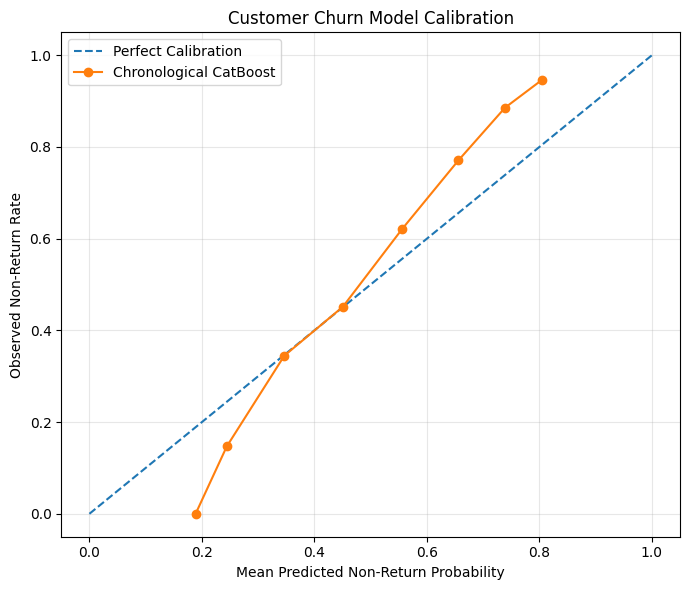


2. CALIBRATION METRICS
Brier Score: 0.1705
Weighted Average Absolute Calibration Gap: 0.0991

3. FILE SAVED: step40_chronological_churn_calibration_analysis.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from google.colab import files
from sklearn.metrics import brier_score_loss

# Use the July 2011 predictions from Step 39
calibration_df = pd.DataFrame({
    "Actual_Non_Return": np.asarray(y_chrono_test),
    "Predicted_Probability": chrono_test_prob
})

# Divide predicted probabilities into 10 equal-width bins
bin_edges = np.linspace(0, 1, 11)

calibration_df["Probability_Bin"] = pd.cut(
    calibration_df["Predicted_Probability"],
    bins=bin_edges,
    include_lowest=True
)

calibration_summary_df = (
    calibration_df.groupby(
        "Probability_Bin",
        observed=False
    )
    .agg(
        Customers=("Actual_Non_Return", "size"),
        Mean_Predicted_Risk=("Predicted_Probability", "mean"),
        Actual_Non_Return_Rate=("Actual_Non_Return", "mean")
    )
    .reset_index()
)

# Keep only bins containing customers
calibration_summary_df = calibration_summary_df.loc[
    calibration_summary_df["Customers"] > 0
].copy()

# Difference between predicted and observed risk
calibration_summary_df["Calibration_Gap"] = (
    calibration_summary_df["Mean_Predicted_Risk"] -
    calibration_summary_df["Actual_Non_Return_Rate"]
)

print("1. CALIBRATION SUMMARY")
display(calibration_summary_df.round(4))

# Draw reliability diagram
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    calibration_summary_df["Mean_Predicted_Risk"],
    calibration_summary_df["Actual_Non_Return_Rate"],
    marker="o",
    label="Chronological CatBoost"
)

plt.xlabel("Mean Predicted Non-Return Probability")
plt.ylabel("Observed Non-Return Rate")
plt.title("Customer Churn Model Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Overall metrics
brier = brier_score_loss(
    y_chrono_test,
    chrono_test_prob
)

weighted_abs_gap = np.average(
    np.abs(calibration_summary_df["Calibration_Gap"]),
    weights=calibration_summary_df["Customers"]
)

print("\n2. CALIBRATION METRICS")
print("Brier Score:", round(brier, 4))
print("Weighted Average Absolute Calibration Gap:", round(weighted_abs_gap, 4))

# Save results
os.makedirs(output_folder, exist_ok=True)

filename = "step40_chronological_churn_calibration_analysis.csv"

filepath = os.path.join(output_folder, filename)

calibration_summary_df.to_csv(filepath, index=False)

print("\n3. FILE SAVED:", filename)

files.download(filepath)


In [51]:

import numpy as np
import pandas as pd
import os
import joblib
import zipfile

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
    average_precision_score
)
from google.colab import files

# ------------------------------------------------
# 1. Fit sigmoid calibrator on APRIL validation
# ------------------------------------------------

# Original model probabilities for April
april_prob = chrono_model.predict_proba(
    X_chrono_val
)[:, 1]

# Clip probabilities for stable logit conversion
eps = 1e-6

def probability_to_logit(prob):
    prob = np.clip(prob, eps, 1 - eps)
    return np.log(prob / (1 - prob)).reshape(-1, 1)

# Train probability calibrator
churn_calibrator = LogisticRegression(
    random_state=42,
    max_iter=1000
)

churn_calibrator.fit(
    probability_to_logit(april_prob),
    y_chrono_val
)

print("1. CALIBRATOR TRAINED")
print("Method: Sigmoid / Platt scaling")

# ------------------------------------------------
# 2. Apply calibration to JULY probabilities
# ------------------------------------------------

july_original_prob = chrono_model.predict_proba(
    X_chrono_test
)[:, 1]

july_calibrated_prob = churn_calibrator.predict_proba(
    probability_to_logit(july_original_prob)
)[:, 1]

# ------------------------------------------------
# 3. Compare probability quality
# ------------------------------------------------

def probability_metrics(actual, probabilities):
    return {
        "Brier_Score": brier_score_loss(
            actual, probabilities
        ),
        "Log_Loss": log_loss(
            actual, probabilities
        ),
        "ROC_AUC": roc_auc_score(
            actual, probabilities
        ),
        "PR_AUC": average_precision_score(
            actual, probabilities
        )
    }

calibration_comparison_df = pd.DataFrame([
    {
        "Model": "Original Chronological CatBoost",
        **probability_metrics(
            y_chrono_test,
            july_original_prob
        )
    },
    {
        "Model": "Calibrated Chronological CatBoost",
        **probability_metrics(
            y_chrono_test,
            july_calibrated_prob
        )
    }
])

print("\n2. JULY PROBABILITY COMPARISON")
display(calibration_comparison_df.round(4))

# ------------------------------------------------
# 4. Examine calibration by probability range
# ------------------------------------------------

calibration_check_df = pd.DataFrame({
    "Actual_Non_Return": np.asarray(y_chrono_test),
    "Original_Probability": july_original_prob,
    "Calibrated_Probability": july_calibrated_prob
})

calibration_check_df["Calibrated_Bin"] = pd.cut(
    calibration_check_df["Calibrated_Probability"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

calibrated_bins_df = (
    calibration_check_df.groupby(
        "Calibrated_Bin",
        observed=False
    )
    .agg(
        Customers=("Actual_Non_Return", "size"),
        Mean_Calibrated_Risk=(
            "Calibrated_Probability", "mean"
        ),
        Actual_Non_Return_Rate=(
            "Actual_Non_Return", "mean"
        )
    )
    .reset_index()
)

calibrated_bins_df = calibrated_bins_df.loc[
    calibrated_bins_df["Customers"] > 0
].copy()

calibrated_bins_df["Calibration_Gap"] = (
    calibrated_bins_df["Mean_Calibrated_Risk"]
    - calibrated_bins_df["Actual_Non_Return_Rate"]
)

print("\n3. CALIBRATED PROBABILITY BINS")
display(calibrated_bins_df.round(4))

# ------------------------------------------------
# 5. Save calibrated probabilities and calibrator
# ------------------------------------------------

os.makedirs(output_folder, exist_ok=True)

comparison_path = os.path.join(
    output_folder,
    "step41_original_vs_calibrated_churn_metrics.csv"
)

bins_path = os.path.join(
    output_folder,
    "step41_calibrated_probability_bins.csv"
)

predictions_path = os.path.join(
    output_folder,
    "step41_calibrated_july_customer_predictions.csv"
)

calibrator_path = os.path.join(
    output_folder,
    "step41_churn_probability_calibrator.joblib"
)

calibration_comparison_df.to_csv(
    comparison_path, index=False
)

calibrated_bins_df.to_csv(
    bins_path, index=False
)

prediction_export = chrono_test_df[
    ["Customer_ID", "Snapshot_Date", "Churn_90D"]
].copy()

prediction_export["Original_Probability"] = (
    july_original_prob
)

prediction_export["Calibrated_Probability"] = (
    july_calibrated_prob
)

prediction_export.to_csv(
    predictions_path, index=False
)

joblib.dump(churn_calibrator, calibrator_path)

# Download all outputs
zip_path = os.path.join(
    output_folder,
    "step41_churn_probability_calibration_files.zip"
)

with zipfile.ZipFile(zip_path, "w") as z:
    for path in [
        comparison_path,
        bins_path,
        predictions_path,
        calibrator_path
    ]:
        z.write(path, arcname=os.path.basename(path))

print("\n4. FILES SAVED SUCCESSFULLY")
for path in [
    comparison_path,
    bins_path,
    predictions_path,
    calibrator_path
]:
    print(os.path.basename(path))

files.download(zip_path)


1. CALIBRATOR TRAINED
Method: Sigmoid / Platt scaling

2. JULY PROBABILITY COMPARISON


,Model,Brier_Score,Log_Loss,ROC_AUC,PR_AUC
0,Original Chronological CatBoost,0.1705,0.5229,0.813,0.8739
1,Calibrated Chronological CatBoost,0.1587,0.4874,0.813,0.8739



3. CALIBRATED PROBABILITY BINS


,Calibrated_Bin,Customers,Mean_Calibrated_Risk,Actual_Non_Return_Rate,Calibration_Gap
0,"(-0.001, 0.1]",43,0.0904,0.0000,0.0904
1,"(0.1, 0.2]",468,0.1409,0.1453,-0.0044
2,"(0.2, 0.3]",333,0.2494,0.2763,-0.0268
3,"(0.3, 0.4]",225,0.3500,0.4044,-0.0544
4,"(0.4, 0.5]",217,0.4513,0.4516,-0.0003
5,"(0.5, 0.6]",281,0.5530,0.5730,-0.0200
6,"(0.6, 0.7]",486,0.6532,0.6276,0.0256
7,"(0.7, 0.8]",975,0.7543,0.7518,0.0025
8,"(0.8, 0.9]",1439,0.8439,0.8603,-0.0164
9,"(0.9, 1.0]",549,0.9196,0.9454,-0.0257



4. FILES SAVED SUCCESSFULLY
step41_original_vs_calibrated_churn_metrics.csv
step41_calibrated_probability_bins.csv
step41_calibrated_july_customer_predictions.csv
step41_churn_probability_calibrator.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:

import os
import json
import shutil
import zipfile
import joblib
import pandas as pd

from google.colab import files

# Create deployment folder
deployment_folder = (
    "/content/Customer_Intelligence_Deployment"
)

models_folder = os.path.join(
    deployment_folder, "models"
)

os.makedirs(models_folder, exist_ok=True)

# Existing trained model locations
source_files = {
    "rfm_standard_scaler.joblib":
        os.path.join(
            output_folder,
            "step23_rfm_standard_scaler.joblib"
        ),
    "customer_segmentation_kmeans.joblib":
        os.path.join(
            output_folder,
            "step26_kmeans_4_clusters.joblib"
        ),
    "churn_catboost.cbm":
        os.path.join(
            output_folder,
            "step37_chronological_catboost_model.cbm"
        ),
    "churn_probability_calibrator.joblib":
        os.path.join(
            output_folder,
            "step41_churn_probability_calibrator.joblib"
        )
}

# Check all model files exist
print("1. VERIFYING MODEL FILES")

for filename, source in source_files.items():
    if not os.path.exists(source):
        raise FileNotFoundError(source)

    shutil.copy2(
        source,
        os.path.join(models_folder, filename)
    )

    print("Verified:", filename)

# Define model input features in exact training order
model_config = {
    "project": "AI Customer Behavior, Churn Risk & Sales Intelligence",

    "segmentation": {
        "algorithm": "KMeans",
        "n_clusters": 4,
        "input_features": [
            "Recency_Days",
            "Frequency",
            "Monetary"
        ],
        "preprocessing": [
            "numpy.log1p",
            "StandardScaler"
        ],
        "segment_names": {
            "0": "Previously Active Customers",
            "1": "Recent Developing Customers",
            "2": "High-Value Active Customers",
            "3": "Infrequent / Inactive Customers"
        },
        "training_reference_date": "2011-12-10"
    },

    "churn_prediction": {
        "algorithm": "CatBoostClassifier",
        "prediction_target": "No recorded positive merchandise purchase within 90 days",
        "feature_columns": [
            "Frequency",
            "Monetary",
            "Total_Units",
            "Unique_Products",
            "Recency_Days",
            "Customer_Tenure_Days",
            "Avg_Invoice_Value",
            "Active_Months"
        ],
        "probability_calibration": "Platt scaling",
        "calibration_input": "Logit of CatBoost probability",
        "probability_threshold": None,
        "training_snapshots": [
            "2010-10-01",
            "2011-01-01"
        ],
        "calibration_snapshot": "2011-04-01",
        "evaluation_snapshot": "2011-07-01",
        "forecast_horizon_days": 90
    }
}

# Save deployment configuration
config_path = os.path.join(
    deployment_folder,
    "model_config.json"
)

with open(config_path, "w") as f:
    json.dump(model_config, f, indent=4)

# Verify loaded model objects
scaler_check = joblib.load(
    os.path.join(
        models_folder, "rfm_standard_scaler.joblib"
    )
)

kmeans_check = joblib.load(
    os.path.join(
        models_folder,
        "customer_segmentation_kmeans.joblib"
    )
)

calibrator_check = joblib.load(
    os.path.join(
        models_folder,
        "churn_probability_calibrator.joblib"
    )
)

assert kmeans_check.n_clusters == 4
assert scaler_check.n_features_in_ == 3
assert calibrator_check.n_features_in_ == 1

print("\n2. DEPLOYMENT CONFIGURATION")
print(json.dumps(model_config, indent=2))

# Package all deployment files
zip_path = (
    "/content/step42_customer_intelligence_model_bundle.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, filenames in os.walk(
        deployment_folder
    ):
        for filename in filenames:

            filepath = os.path.join(root, filename)

            archive_name = os.path.relpath(
                filepath,
                deployment_folder
            )

            z.write(
                filepath,
                arcname=archive_name
            )

print("\n3. MODEL BUNDLE CREATED")
print("Filename:", os.path.basename(zip_path))
print(
    "Size:",
    round(os.path.getsize(zip_path) / (1024 * 1024), 2),
    "MB"
)

print("\n4. ALL MODELS PACKAGED SUCCESSFULLY")

files.download(zip_path)


1. VERIFYING MODEL FILES
Verified: rfm_standard_scaler.joblib
Verified: customer_segmentation_kmeans.joblib
Verified: churn_catboost.cbm
Verified: churn_probability_calibrator.joblib

2. DEPLOYMENT CONFIGURATION
{
  "project": "AI Customer Behavior, Churn Risk & Sales Intelligence",
  "segmentation": {
    "algorithm": "KMeans",
    "n_clusters": 4,
    "input_features": [
      "Recency_Days",
      "Frequency",
      "Monetary"
    ],
    "preprocessing": [
      "numpy.log1p",
      "StandardScaler"
    ],
    "segment_names": {
      "0": "Previously Active Customers",
      "1": "Recent Developing Customers",
      "2": "High-Value Active Customers",
      "3": "Infrequent / Inactive Customers"
    },
    "training_reference_date": "2011-12-10"
  },
  "churn_prediction": {
    "algorithm": "CatBoostClassifier",
    "prediction_target": "No recorded positive merchandise purchase within 90 days",
    "feature_columns": [
      "Frequency",
      "Monetary",
      "Total_Units",
    

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:

import numpy as np
import pandas as pd

# ==========================================
# 1. SELECT AN EXAMPLE CUSTOMER
# ==========================================

customer_id = "12347"

# Select historical customer information
# as of July 1, 2011
example = chrono_test_df[
    chrono_test_df["Customer_ID"].astype(str) == customer_id
].copy()

if example.empty:
    raise ValueError("Customer not found!")

print("1. CUSTOMER DETAILS")

display(example[
    [
        "Customer_ID",
        "Frequency",
        "Monetary",
        "Recency_Days",
        "Active_Months",
        "Churn_90D"
    ]
])

# ==========================================
# 2. TEST K-MEANS SEGMENTATION MODEL
# ==========================================

rfm_features = [
    "Recency_Days",
    "Frequency",
    "Monetary"
]

# Apply same transformation used in training
rfm_log = np.log1p(example[rfm_features])

rfm_scaled = scaler_check.transform(rfm_log)

# Predict customer segment
cluster = int(kmeans_check.predict(rfm_scaled)[0])

segment_names = {
    0: "Previously Active Customers",
    1: "Recent Developing Customers",
    2: "High-Value Active Customers",
    3: "Infrequent / Inactive Customers"
}

segment = segment_names[cluster]

print("\n2. CUSTOMER SEGMENTATION RESULT")
print("Customer ID:", customer_id)
print("Cluster:", cluster)
print("Customer Segment:", segment)

# ==========================================
# 3. TEST CATBOOST CHURN MODEL
# ==========================================

churn_features = [
    "Frequency",
    "Monetary",
    "Total_Units",
    "Unique_Products",
    "Recency_Days",
    "Customer_Tenure_Days",
    "Avg_Invoice_Value",
    "Active_Months"
]

# Predict probability of no purchase
raw_probability = chrono_model.predict_proba(
    example[churn_features]
)[0, 1]

# Convert probability to logit for calibrator
safe_probability = np.clip(
    raw_probability, 1e-6, 1 - 1e-6
)

logit = np.log(
    safe_probability / (1 - safe_probability)
)

# Apply trained probability calibration
calibrated_probability = calibrator_check.predict_proba(
    np.array([[logit]])
)[0, 1]

print("\n3. CUSTOMER CHURN PREDICTION")
print("Original probability:", round(raw_probability * 100, 2), "%")
print("Calibrated non-return probability:",
      round(calibrated_probability * 100, 2), "%")

# Illustrative risk bands, not validated business thresholds
if calibrated_probability >= 0.75:
    risk_level = "High"
elif calibrated_probability >= 0.40:
    risk_level = "Medium"
else:
    risk_level = "Low"

print("Illustrative risk category:", risk_level)

# ==========================================
# 4. CHECK ACTUAL HISTORICAL OUTCOME
# ==========================================

actual = int(example["Churn_90D"].iloc[0])

print("\n4. HISTORICAL OUTCOME")

if actual == 1:
    print("Actual result: Customer did NOT purchase in the next 90 days.")
else:
    print("Actual result: Customer DID purchase in the next 90 days.")

print("\nMODEL TEST COMPLETED!")


1. CUSTOMER DETAILS


,Customer_ID,Frequency,Monetary,Recency_Days,Active_Months,Churn_90D
12545,12347,5,2817.48,21.457639,5,0



2. CUSTOMER SEGMENTATION RESULT
Customer ID: 12347
Cluster: 1
Customer Segment: Recent Developing Customers

3. CUSTOMER CHURN PREDICTION
Original probability: 30.99 %
Calibrated non-return probability: 23.2 %
Illustrative risk category: Low

4. HISTORICAL OUTCOME
Actual result: Customer DID purchase in the next 90 days.

MODEL TEST COMPLETED!
